# 03 · Selección, EDA y plan de preprocesado del Tema 1

Paso 3 de la descarga completa ([plan de la descarga](../../../docs/fase2/mercados_series/PLAN_DESCARGA.md)).
Viene del [inventario del paso 2](02_inventario.ipynb).

**En una frase:** a partir del inventario del paso 2, este paso decide qué series y qué ficheros de precios se
quedan, revisa lo que se queda (EDA: solo marca, no corrige) y deja escrito un plan de preprocesado que solo
puede **retrasar** fechas de publicación, nunca adelantarlas. Al final recoge las decisiones de cierre F1–F5 del
usuario (sección 11). El notebook lee tablas de metadatos y YAML y, en la sección 11, solo las columnas de **fechas**
de la base de las series afectadas por F1–F2: no hay ni un valor de serie ni un precio, y todas las cifras salen de
las celdas.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ['png']
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import Markdown, display
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch

from ingesta.comun.rutas import resultados_dir
from ingesta.mercados_series import eda, inventario, preprocesado, seleccion

plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 9, 'axes.titlesize': 11,
                     'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white'})
pd.set_option('display.max_rows', 20)
pd.set_option('display.max_colwidth', 100)

# Paleta única del notebook: decisión (queda / alias / proyecciones / fuera) y, dentro de «queda», el rol (verdes)
COL_DEC = {'queda': '#2b8a3e', 'alias': '#74c0fc', 'proyecciones': '#b197fc', 'fuera': '#ced4da'}
COL = {'unica': '#2b8a3e', 'canonico': '#51cf66', 'validacion': '#b2f2bb', 'historia_previa': '#087f5b',
       'alias': COL_DEC['alias'], 'proyeccion': COL_DEC['proyecciones'], 'fuera': COL_DEC['fuera']}
ETQ = {'unica': 'queda · única', 'canonico': 'queda · canónico', 'validacion': 'queda · validación',
       'historia_previa': 'queda · historia previa', 'alias': 'alias', 'proyeccion': 'proyecciones (tabla aparte)',
       'fuera': 'fuera'}
ROLES_QUEDA = ['unica', 'canonico', 'validacion', 'historia_previa']
ROLES = ROLES_QUEDA + ['alias', 'proyeccion', 'fuera']
# Trato de la fecha (D2): verde sin aviso; naranjas, con fecha conservadora (más oscuro, más conservador)
COL_TRATO = {'entra sin aviso': '#2b8a3e', 'entra con tramo conservador (E5)': '#ffa94d',
             'entra con aviso y regla conservadora (E4)': '#d9480f'}
CMAP_INC = 'YlOrRd'                                      # los dos mapas de incidencias del EDA
COL_P = {'alta': '#c92a2a', 'media': '#ff8787', 'baja': '#ffd8d8'}   # prioridades del 3b
FUENTE_TXT = {'worldbank': 'Banco Mundial', 'imf_weo': 'WEO del FMI', 'fred_alfred': 'FRED/ALFRED'}


def es(x, d=0):
    # número en formato español: 1.434 · 0,95
    s = f'{x:,.{d}f}'
    return s.replace(',', '§').replace('.', ',').replace('§', '.')


def dias(x):
    return f"{es(x)} {'día' if x == 1 else 'días'}"


T = resultados_dir('mercados_series') / 'tablas'
sel = pd.read_csv(T / 'seleccion_series.csv')
selp = pd.read_csv(T / 'seleccion_precios.csv', dtype={'id': str})
d3b = pd.read_csv(T / 'descargas_3b.csv')
edas = pd.read_csv(T / 'eda_series.csv')
incs = pd.read_csv(T / 'eda_series_incidencias.csv')
edap = pd.read_csv(T / 'eda_precios.csv', dtype={'ticker': str})
incp = pd.read_csv(T / 'eda_precios_incidencias.csv', dtype={'ticker': str})
sim = pd.read_csv(T / 'preprocesado_simulacion.csv')
inv = pd.read_csv(T / 'inventario_series.csv')
invp = pd.read_csv(T / 'inventario_precios.csv', dtype={'ticker': str})
fia = pd.read_csv(T / 'fiabilidad_c.csv')
res = pd.read_csv(T / 'seleccion_resumen.csv')
PLAN = preprocesado.cargar_plan()      # borrador validado (falla si no casa con lags.yaml y publicaciones.yaml)
LISTA = preprocesado.cargar_lista()    # config/lista_curada.yaml: fuente de verdad del paso 4
LISTA_P = yaml.safe_load(preprocesado.RUTA_LISTA.read_text(encoding='utf-8'))['precios']

q = sel['decision'] == 'queda'
qp = selp['decision'] == 'queda'
n = lambda m: int(np.sum(m))

# Coherencia: las mismas series y ficheros que el inventario del 02, y la lista YAML dice lo mismo que las tablas
assert len(sel) == len(inv) and set(sel['id']) == set(inv['id']), 'seleccion_series.csv no cubre el inventario'
assert len(selp) == len(invp) and set(selp['id']) == set(invp['ticker']), 'seleccion_precios.csv no cubre el inventario'
assert pd.Series({k: v['decision'] for k, v in LISTA.items()}).reindex(sel['id']).tolist() == sel['decision'].tolist()
assert pd.Series({str(k): v['decision'] for k, v in LISTA_P.items()}).reindex(selp['id']).tolist() == selp['decision'].tolist()
tot_res = res[res['desglose'] == 'total'].groupby('tipo')['n'].sum()
assert tot_res['series'] == len(sel) and tot_res['precios'] == len(selp), 'seleccion_resumen.csv no cuadra'
print(f'Inventario del paso 2: {es(len(inv))} series y {es(len(invp))} ficheros de precios. lista_curada.yaml, '
      'seleccion_*.csv y seleccion_resumen.csv cuadran con él entrada a entrada.')

Inventario del paso 2: 1.434 series y 1.471 ficheros de precios. lista_curada.yaml, seleccion_*.csv y seleccion_resumen.csv cuadran con él entrada a entrada.


## Resumen ejecutivo

Las ocho cifras que resumen el paso, calculadas aquí mismo a partir de las tablas, y las conclusiones.

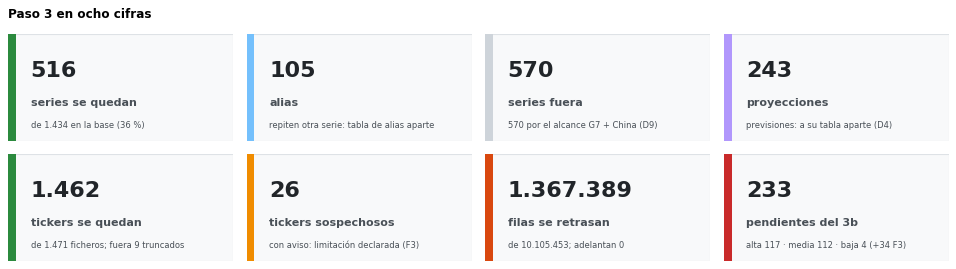

- **Se quedan 516 de 1.434 series.** Lo que sale es sobre todo Banco Mundial fuera del alcance estricto (570) y las previsiones del WEO del FMI (240), que van a su tabla; los 105 alias se guardan aparte para contrastar.
- **Los precios se quedan casi enteros (1.462 de 1.471 ficheros):** D10 sigue abierta, así que solo salen los 9 ficheros truncados. Solo Yahoo (F3): los 26 tickers sospechosos se quedan con aviso como limitación declarada.
- **El plan de preprocesado es seguro:** retrasaría 1.367.389 filas de 10.105.453 (13,5 %) y no adelanta ninguna. **Todas las fechas de publicación que usa están verificadas o son conservadoras:** ninguna regla queda pendiente de calendario, y las 10 fechas de creación externas están comprobadas en la web (F1–F2).
- **El paso 3b puede empezar:** 233 descargas pendientes (alta 117 · media 112 · baja 4) y 34 filas que no se descargan por limitación declarada (F3).

In [2]:
tot = sim[sim['seccion'] == 'total'].iloc[0]
n_fuera_d9 = n(sel['regla'] == 'D9_fuera_alcance')
proy = sel[sel['decision'] == 'proyecciones']
n_sos = n(qp & selp['aviso'].fillna('').str.contains('sospechosa'))
pend3b = d3b[d3b['estado'] == 'pendiente']
lim3b = d3b[d3b['estado'] == 'limitacion_declarada']
pr3b = pend3b['prioridad'].value_counts().reindex(['alta', 'media', 'baja'], fill_value=0)
# Fechas del plan: ¿queda alguna regla pendiente de calendario?
n_pend_plan = (sum(bool(e.get('pendiente_calendario')) for gr in PLAN['reglas_conservadoras'].values()
                   for e in gr['reglas'].values())
               + len(PLAN['reconstruidas'].get('pendiente_calendario') or {})
               + n(sim['pendiente_calendario'].astype(str).eq('True')))
EXT = PLAN['reconstruidas']['externas']
TARJETAS = [
    (es(n(q)), 'series se quedan', f'de {es(len(sel))} en la base ({es(100 * n(q) / len(sel))} %)', COL_DEC['queda']),
    (es(n(sel['decision'] == 'alias')), 'alias', 'repiten otra serie: tabla de alias aparte', COL_DEC['alias']),
    (es(n(sel['decision'] == 'fuera')), 'series fuera', f'{es(n_fuera_d9)} por el alcance G7 + China (D9)', COL_DEC['fuera']),
    (es(len(proy)), 'proyecciones', 'previsiones: a su tabla aparte (D4)', COL_DEC['proyecciones']),
    (es(n(qp)), 'tickers se quedan', f'de {es(len(selp))} ficheros; fuera {n(~qp)} truncados', COL_DEC['queda']),
    (es(n_sos), 'tickers sospechosos', 'con aviso: limitación declarada (F3)', '#f08c00'),
    (es(int(tot['filas_cambian'])), 'filas se retrasan', f"de {es(int(tot['filas_regla']))}; adelantan {int(tot['filas_adelantan'])}",
     COL_TRATO['entra con aviso y regla conservadora (E4)']),
    (es(len(pend3b)), 'pendientes del 3b',
     f"alta {pr3b['alta']} · media {pr3b['media']} · baja {pr3b['baja']} (+{len(lim3b)} F3)", COL_P['alta']),
]
fig, axs = plt.subplots(2, 4, figsize=(12, 3.3), gridspec_kw={'wspace': .06, 'hspace': .12})
for ax, (cifra, etq, sub, color) in zip(axs.ravel(), TARJETAS):
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, fc='#f8f9fa', ec='#dee2e6', transform=ax.transAxes))
    ax.add_patch(plt.Rectangle((0, 0), .035, 1, fc=color, ec='none', transform=ax.transAxes))
    ax.text(.1, .66, cifra, fontsize=20, fontweight='bold', color='#212529', va='center', transform=ax.transAxes)
    ax.text(.1, .36, etq, fontsize=10, fontweight='bold', color='#495057', va='center', transform=ax.transAxes)
    ax.text(.1, .15, sub, fontsize=7.5, color='#495057', va='center', transform=ax.transAxes)
    ax.axis('off')
fig.suptitle('Paso 3 en ocho cifras', fontweight='bold', x=.01, ha='left')
fig.subplots_adjust(left=.01, right=.99, top=.88, bottom=.02)
plt.show()

g_fuera = FUENTE_TXT.get(sel.loc[sel['decision'] == 'fuera', 'fuente'].mode()[0])
g_proy = FUENTE_TXT.get(proy['fuente'].mode()[0])
txt_pend = ('ninguna regla queda pendiente de calendario' if n_pend_plan == 0
            else f'quedan {n_pend_plan} reglas pendientes de calendario')
display(Markdown(
    f"- **Se quedan {es(n(q))} de {es(len(sel))} series.** Lo que sale es sobre todo {g_fuera} fuera del alcance "
    f"estricto ({es(n_fuera_d9)}) y las previsiones del {g_proy} ({es(n(proy['fuente'] == 'imf_weo'))}), que van a "
    f"su tabla; los {n(sel['decision'] == 'alias')} alias se guardan aparte para contrastar.\n"
    f"- **Los precios se quedan casi enteros ({es(n(qp))} de {es(len(selp))} ficheros):** D10 sigue abierta, así que "
    f"solo salen los {n(~qp)} ficheros truncados. Solo Yahoo (F3): los {n_sos} tickers sospechosos se quedan con aviso "
    "como limitación declarada.\n"
    f"- **El plan de preprocesado es seguro:** retrasaría {es(int(tot['filas_cambian']))} filas de "
    f"{es(int(tot['filas_regla']))} ({es(100 * tot['filas_cambian'] / tot['filas_regla'], 1)} %) y no adelanta "
    f"ninguna. **Todas las fechas de publicación que usa están verificadas o son conservadoras:** {txt_pend}, y las "
    f"{len(EXT)} fechas de creación externas están comprobadas en la web (F1–F2).\n"
    f"- **El paso 3b puede empezar:** {len(pend3b)} descargas pendientes (alta {pr3b['alta']} · media {pr3b['media']} "
    f"· baja {pr3b['baja']}) y {len(lim3b)} filas que no se descargan por limitación declarada (F3)."))

## 0. Qué hace este paso y vocabulario

**Qué se ve:** qué lee y qué escribe el paso, el vocabulario y los umbrales. **Conclusión:** el notebook no
calcula nada pesado; lee lo que escriben tres órdenes del módulo.

El paso **aplica las decisiones ya tomadas** a cada serie y a cada fichero de precios: las **D1–D10** del paso 2 y
las **E1–E7** de este paso (la sección 1 las resume una a una). Saca la **lista curada**: para cada entrada, «se
queda», «alias de X», «fuera» o «proyección», con su motivo. Después hace un **EDA sencillo** de lo que se queda,
deja escrito el **plan del preprocesado del paso 4 sin aplicarlo** (solo lo simula para contar filas) y **lista lo
que falta por descargar** en el paso 3b.

| Lee | Escribe (lo hacen los módulos; aquí solo se lee) |
|---|---|
| `tablas/inventario_series.csv`, `inventario_precios.csv`, `fiabilidad_c.csv` (paso 2) | `config/lista_curada.yaml` y `tablas/seleccion_series.csv`, `seleccion_precios.csv`, `seleccion_resumen.csv` (orden `seleccion`) |
| `tablas/redundancia_*.csv` (paso 2) | `tablas/descargas_3b.csv` (orden `seleccion`) |
| La base de series y los ficheros de precios del corpus (solo los módulos, no este notebook) | `tablas/eda_series.csv`, `eda_series_incidencias.csv`, `eda_precios.csv`, `eda_precios_incidencias.csv`, `eda_resumen.csv` (orden `eda`) |
| `config/catalogo_series.yaml`, `publicaciones.yaml`, `lags.yaml`, `universo.yaml` | `config/preprocesado.yaml` (borrador a mano, validado por `preprocesado.cargar_plan`) y `tablas/preprocesado_simulacion.csv` (orden `preprocesado`) |

Orden de regeneración: `python -m ingesta.mercados_series eda`, luego `seleccion` (lee `eda_precios.csv`) y luego
`preprocesado` (lee la lista curada).

**Vocabulario** (cada término, la primera vez que hace falta):

- **Vintage**: cada versión publicada de un dato; ALFRED (el archivo de FRED) guarda las antiguas.
- **Fecha de publicación**: el día en que el dato se pudo ver; manda en el backtest (no la fecha de referencia, el
  periodo al que se refiere el dato).
- **Nivel de fecha A–D**: lo fiable que es esa fecha. **A**, exacta o contrastada con ALFRED; **B**, regla de
  calendario verificada; **C**, regla sin verificar; **D**, sin fecha (sale).
- **Canónico**: la serie que se queda como referencia cuando varias fuentes miden lo mismo (E1).
- **Alias**: serie que repite a su canónico; se guarda en una tabla aparte, no en la base curada.
- **Regla estrella** (D8): una serie solo es alias si se parece **directamente** al canónico, no por cadena (si A
  se parece a B y B a C, A y C no se dan por iguales sin compararlas).
- **Validación**: del mismo grupo que un canónico, pero sin llegar a alias; se queda para contrastar.
- **No medible**: no hay con qué contrastar su fecha de publicación (no hay archivo de ediciones).
- **No fiable**: la regla de fecha **adelanta** a la fecha real medida en algún tramo (vería el futuro).
- **Regla conservadora** (E4): para las no medibles, la fecha más tardía plausible según el calendario de la fuente.
- **Tramo conservador** (E5): en las no fiables, antes de la fecha desde la que son fiables (`fiable_desde`) se usa
  la regla más el mayor adelanto medido más un margen.
- **Q1**: la pregunta del plan de datos sobre la fuente final de precios; decidida en F3: **solo Yahoo**.
- **Limitación declarada** (F3): lo que Yahoo no tiene (deslistados, tickers sospechosos, algún instrumento) no se
  descarga de otra fuente: se declara como limitación y su sesgo se mide.
- **Frontera**: dato que puede solaparse con otro tema del equipo (Temas 2, 3 y 4).
- **F1–F5**: las decisiones de cierre de este paso (sección 11).

Los umbrales que usan los módulos (constantes del código, no se escriben a mano):

In [3]:
CONSTANTES = [('seleccion', 'UMBRAL_ALIAS', 'D8: |correlación de los cambios| para ser alias'),
              ('seleccion', 'SOLAPE_ALIAS', 'D8: años de solape mínimo'),
              ('seleccion', 'UMBRAL_ETF', 'correlación mínima en un grupo de ETF'),
              ('seleccion', 'MIN_SESIONES', 'sesiones mínimas de un fichero (si no, truncado)'),
              ('seleccion', 'MARGEN_HISTORIA_DIAS', 'E1: días de historia que puede perder un canónico sin ser dudoso'),
              ('inventario', 'CORTE_2000', 'D1: primera publicación visible como tarde'),
              ('eda', 'UMBRAL_MAD', 'salto: desviaciones robustas'),
              ('eda', 'MIN_HUECO', 'hueco largo: periodos seguidos sin dato'),
              ('eda', 'FACTOR_UNIDAD', 'cambio de unidad entre vintages: factor'),
              ('eda', 'UMBRAL_SALTO_PRECIO', 'salto sin split: |Δlog| del cierre'),
              ('eda', 'SOSPECHA_SALTOS', 'ticker sospechoso: saltos sin split'),
              ('eda', 'SOSPECHA_PCT_REPETIDO', 'ticker sospechoso: % de cierres repetidos'),
              ('eda', 'SOSPECHA_PCT_APERTURA', 'ticker sospechoso: % de aperturas de relleno')]
MODS = {'seleccion': seleccion, 'inventario': inventario, 'eda': eda}


def valor(v):
    return str(v.date()) if hasattr(v, 'date') else str(v)


pd.DataFrame({'constante': [f'{m}.{c}' for m, c, _ in CONSTANTES],
              'dato': [valor(getattr(MODS[m], c)) for m, c, _ in CONSTANTES],
              'para qué': [p for _, _, p in CONSTANTES]})

,constante,dato,para qué
0,seleccion.UMBRAL_ALIAS,0.95,D8: |correlación de los cambios| para ser alias
1,seleccion.SOLAPE_ALIAS,5.0,D8: años de solape mínimo
2,seleccion.UMBRAL_ETF,0.98,correlación mínima en un grupo de ETF
3,seleccion.MIN_SESIONES,20,"sesiones mínimas de un fichero (si no, truncado)"
4,seleccion.MARGEN_HISTORIA_DIAS,365,E1: días de historia que puede perder un canónico sin ser dudoso
5,inventario.CORTE_2000,2001-01-02,D1: primera publicación visible como tarde
6,eda.UMBRAL_MAD,8.0,salto: desviaciones robustas
7,eda.MIN_HUECO,3,hueco largo: periodos seguidos sin dato
8,eda.FACTOR_UNIDAD,10.0,cambio de unidad entre vintages: factor
9,eda.UMBRAL_SALTO_PRECIO,0.4,salto sin split: |Δlog| del cierre


## 1. Las decisiones aplicadas

**Qué se ve:** cada decisión del [plan](../../../docs/fase2/mercados_series/PLAN_DESCARGA.md), qué regla aplica y
a cuántas series o tickers toca (contado en `seleccion_series.csv` y `seleccion_precios.csv`). **Conclusión:** todas
tienen efecto en la lista, salvo D5 (descartada) y D10 (abierta a propósito hasta la Fase 4). Las decisiones de cierre
F1–F5, tomadas después, están en la sección 11.

Primero las del paso 2 (D) y después las de este paso (E):

In [4]:
plazos = sel['id'].map(seleccion.plazo_curva)
n_dudosos = len(seleccion.dudosos(sel, n=len(sel)))
inc_q = set(edas.loc[edas['serie'].isin(sel.loc[q, 'id']) & edas['banderas'].notna(), 'serie'])
inc_qp = set(incp.loc[incp['ticker'].isin(selp.loc[qp, 'id']), 'ticker'])
r = sel['regla'].value_counts()
DEC_D = [
    ('D1', 'Historia desde 2000: primera publicación visible <= inventario.CORTE_2000',
     f"{n(q & sel['desde_2000'])} de {n(q)} series que se quedan la tienen ({n(q & sel['desde_2000_exacto'])} con fecha "
     f"exacta desde antes del corte); {n(qp & selp['desde_2000'])} tickers. No echa a nadie: lo único se queda"),
    ('D2', 'Fiabilidad de la fecha en la ventana desde 2000 (B y C, igual)',
     f"{n(q & sel['aviso_fecha'].isna())} sin aviso · {n(q & (sel['aviso_fecha'] == 'no medible'))} con aviso y regla "
     f"conservadora · {n(q & (sel['aviso_fecha'] == 'no fiable'))} con tramo conservador"),
    ('D3 / D9', 'Alcance estricto: G7 + China (Banco Mundial y WEO)', f"{r.get('D9_fuera_alcance', 0)} series fuera"),
    ('D4', 'Proyecciones (SEP de la Fed y horizontes del WEO) a una tabla aparte', f"{n(sel['decision'] == 'proyecciones')} series"),
    ('D5', 'Agente de cada serie', 'descartada: se decide al construir los agentes'),
    ('D6', 'Ficha del BoE: sin extraer de HTML', f"ninguna serie; las curvas del BoE ya están ({n(q & (sel['fuente'] == 'boe_curvas'))} se quedan)"),
    ('D7', 'Inventario versionado en tablas/inventario_*.csv', f"{es(len(inv))} series y {es(len(selp))} ficheros inventariados"),
    ('D8', 'Alias si |corr. de los cambios| >= UMBRAL_ALIAS con SOLAPE_ALIAS años, regla estrella',
     f"{r.get('D8_estrella', 0)} alias por correlación + {r.get('concepto_confirmado', 0)} por grupo de concepto confirmado"),
    ('D9', 'Banco Mundial / WEO duplicados con una serie de más frecuencia', f"{r.get('D9_mayor_frecuencia', 0)} alias"),
    ('D10', 'Mínimos de un ticker: ABIERTA (elegibilidad punto a punto en la Fase 4)',
     f"{n(selp['regla'] == 'd10_abierta')} tickers sin corte; fuera solo {n(selp['regla'] == 'truncado')} ficheros truncados"),
    ('catálogo', 'estado = duplicada en catalogo_series.yaml', f"{r.get('catalogo_duplicada', 0)} alias"),
]
DEC_E = [
    ('E1', 'Canónico por nivel de fecha > historia > frecuencia > fuente oficial',
     f"{n(q & (sel['rol'] == 'canonico'))} canónicos y {n(q & (sel['rol'] == 'validacion'))} de validación; "
     f"{n_dudosos} canónicos dudosos, aceptados o resueltos a mano (F4, sección 3)"),
    ('E2', 'Los plazos de una curva no son alias entre sí',
     f"{n(q & plazos.notna())} plazos de curva se quedan (de {n(plazos.notna())} en la base)"),
    ('E3', 'Eurostat: zona euro cambiante (EA) y HICP empalmado; el resto, alias', f"{r.get('E3_version_eurostat', 0)} alias"),
    ('D1 > E1', 'Un alias con historia antes del corte de D1 que su canónico no tiene se queda (historia previa)',
     f"{n(sel['rol'] == 'historia_previa')} series"),
    ('E4', 'Regla conservadora de los «no medibles» (calendario documentado)',
     f"{n(q & sel['regla_conservadora'].notna())} series en {sel.loc[q, 'regla_conservadora'].nunique()} grupos"),
    ('E5', 'Tramo «no fiable»: regla + adelanto máximo medido + margen, sin borrar',
     f"{n(q & sel['tramo_conservador_antes_de'].notna())} series ({n(q & (sel['tramo_conservador_antes_de'] == 'toda'))} en toda la serie)"),
    ('E6 / F5', 'Fronteras: lo numérico se queda en el Tema 1; textos e informes, en los Temas 2, 3 y 4 (por confirmar)',
     f"tema2 {n(q & (sel['frontera'] == 'tema2'))} · tema4 {n(q & (sel['frontera'] == 'tema4'))} series; "
     f"tema3 {n(qp & (selp['frontera'] == 'tema3'))} tickers"),
    ('E7', 'EDA: solo detecta y propone, no corrige',
     f"{len(inc_q)} series y {len(inc_qp)} tickers de los que se quedan con alguna incidencia"),
]
COLS_DEC = ['decisión', 'qué se aplica', 'a cuánto toca']
display(pd.DataFrame(DEC_D, columns=COLS_DEC).style.hide(axis='index').set_caption('Decisiones del paso 2 (D)'))
display(pd.DataFrame(DEC_E, columns=COLS_DEC).style.hide(axis='index').set_caption('Decisiones del paso 3 (E)'))

decisión,qué se aplica,a cuánto toca
D1,Historia desde 2000: primera publicación visible <= inventario.CORTE_2000,390 de 516 series que se quedan la tienen (112 con fecha exacta desde antes del corte); 821 tickers. No echa a nadie: lo único se queda
D2,"Fiabilidad de la fecha en la ventana desde 2000 (B y C, igual)",208 sin aviso · 202 con aviso y regla conservadora · 106 con tramo conservador
D3 / D9,Alcance estricto: G7 + China (Banco Mundial y WEO),570 series fuera
D4,Proyecciones (SEP de la Fed y horizontes del WEO) a una tabla aparte,243 series
D5,Agente de cada serie,descartada: se decide al construir los agentes
D6,Ficha del BoE: sin extraer de HTML,ninguna serie; las curvas del BoE ya están (12 se quedan)
D7,Inventario versionado en tablas/inventario_*.csv,1.434 series y 1.471 ficheros inventariados
D8,"Alias si |corr. de los cambios| >= UMBRAL_ALIAS con SOLAPE_ALIAS años, regla estrella",31 alias por correlación + 2 por grupo de concepto confirmado
D9,Banco Mundial / WEO duplicados con una serie de más frecuencia,40 alias
D10,Mínimos de un ticker: ABIERTA (elegibilidad punto a punto en la Fase 4),1462 tickers sin corte; fuera solo 9 ficheros truncados


decisión,qué se aplica,a cuánto toca
E1,Canónico por nivel de fecha > historia > frecuencia > fuente oficial,"77 canónicos y 29 de validación; 20 canónicos dudosos, aceptados o resueltos a mano (F4, sección 3)"
E2,Los plazos de una curva no son alias entre sí,90 plazos de curva se quedan (de 103 en la base)
E3,"Eurostat: zona euro cambiante (EA) y HICP empalmado; el resto, alias",21 alias
D1 > E1,Un alias con historia antes del corte de D1 que su canónico no tiene se queda (historia previa),5 series
E4,Regla conservadora de los «no medibles» (calendario documentado),202 series en 4 grupos
E5,"Tramo «no fiable»: regla + adelanto máximo medido + margen, sin borrar",106 series (12 en toda la serie)
E6 / F5,"Fronteras: lo numérico se queda en el Tema 1; textos e informes, en los Temas 2, 3 y 4 (por confirmar)",tema2 120 · tema4 7 series; tema3 1348 tickers
E7,"EDA: solo detecta y propone, no corrige",348 series y 1453 tickers de los que se quedan con alguna incidencia


## 2. De la base completa a la lista curada

**Qué se ve:** a la izquierda, el embudo: de todas las series se quitan las de fuera del alcance (D3/D9), las
proyecciones (D4) y los alias; a la derecha, el reparto de cada fuente. **Conclusión:** lo que sale es casi todo
Banco Mundial fuera del alcance y previsiones del WEO; dentro de lo que se queda, la mayoría son series únicas.

Lo que se queda se reparte por **rol**:

- **única**: no tiene pareja;
- **canónico**: la que se queda de un grupo de series que miden lo mismo (E1);
- **validación**: del mismo grupo que un canónico, pero sin llegar a alias (no se parece lo bastante, o es de
  otra frecuencia): sirve para contrastar;
- **historia previa**: un alias que se queda porque aporta historia anterior al corte de D1 que su canónico no tiene.

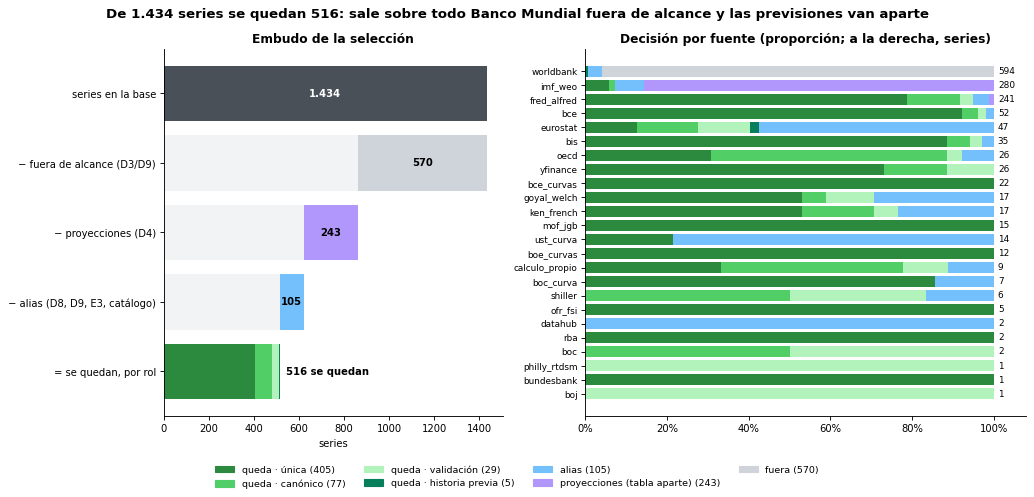

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw={'width_ratios': [1, 1.3]})
total = len(sel)
pasos = [('fuera', 'fuera', '− fuera de alcance (D3/D9)'), ('proyecciones', 'proyeccion', '− proyecciones (D4)'),
         ('alias', 'alias', '− alias (D8, D9, E3, catálogo)')]
a1.barh(4, total, color='#495057')
a1.text(total / 2, 4, es(total), ha='center', va='center', color='white', fontweight='bold')
resto, etiquetas = total, ['series en la base']
for i, (dec, rol, etq) in enumerate(pasos):
    k = n(sel['decision'] == dec)
    resto -= k
    a1.barh(3 - i, resto, color='#f1f3f5')
    a1.barh(3 - i, k, left=resto, color=COL[rol])
    a1.text(resto + k / 2, 3 - i, es(k), ha='center', va='center', fontweight='bold')
    etiquetas.append(etq)
izq = 0
for rol in ROLES_QUEDA:
    k = n(q & (sel['rol'] == rol))
    a1.barh(0, k, left=izq, color=COL[rol])
    izq += k
a1.text(izq + total * .02, 0, f'{es(n(q))} se quedan', va='center', fontweight='bold')
etiquetas.append('= se quedan, por rol')
a1.set_yticks([4, 3, 2, 1, 0], etiquetas)
a1.set_xlabel('series')
a1.set_title('Embudo de la selección')
a1.set_xlim(0, total * 1.05)

ct = pd.crosstab(sel['fuente'], sel['rol']).reindex(columns=ROLES, fill_value=0)
ct = ct.loc[ct.sum(axis=1).sort_values().index]
pr = ct.div(ct.sum(axis=1), axis=0)
izq = np.zeros(len(pr))
for rol in ROLES:
    a2.barh(pr.index, pr[rol], left=izq, color=COL[rol], height=0.8)
    izq += pr[rol].to_numpy()
for y, k in enumerate(ct.sum(axis=1)):
    a2.text(1.01, y, f'{k}', va='center', fontsize=8)
a2.set_xlim(0, 1.08)
a2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
a2.set_title('Decisión por fuente (proporción; a la derecha, series)')
a2.tick_params(axis='y', labelsize=8)
cuenta = sel['rol'].value_counts()
fig.legend(handles=[Patch(color=COL[k], label=f'{ETQ[k]} ({es(cuenta.get(k, 0))})') for k in ROLES],
           loc='lower center', ncol=4, frameon=False, fontsize=8.5)
g_fuera = FUENTE_TXT.get(sel.loc[sel['decision'] == 'fuera', 'fuente'].mode()[0])
fig.suptitle(f'De {es(total)} series se quedan {es(n(q))}: sale sobre todo {g_fuera} fuera de alcance '
             f'y las previsiones van aparte', fontweight='bold', fontsize=12)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

La misma información en tabla, por fuente, con las 12 fuentes más grandes (el resto, agrupado; el detalle
completo está en `seleccion_resumen.csv`):

In [6]:
tabla = pd.crosstab(sel['fuente'], sel['rol']).reindex(columns=ROLES, fill_value=0)
tabla.insert(4, 'queda', tabla[ROLES_QUEDA].sum(axis=1))
tabla['total'] = tabla[ROLES].sum(axis=1)
tabla = tabla.sort_values('total', ascending=False)
grandes, resto_f = tabla.head(12), tabla.iloc[12:]
tabla_v = pd.concat([grandes, resto_f.sum().rename(f'resto ({len(resto_f)} fuentes)').to_frame().T,
                     tabla.sum().rename('total').to_frame().T])
tabla_v.columns.name = None
tabla_v

,unica,canonico,validacion,historia_previa,queda,alias,proyeccion,fuera,total
worldbank,0,0,0,4,4,20,0,570,594
imf_weo,16,4,0,0,20,20,240,0,280
fred_alfred,190,31,8,0,229,9,3,0,241
bce,48,2,1,0,51,1,0,0,52
eurostat,6,7,6,1,20,27,0,0,47
bis,31,2,1,0,34,1,0,0,35
yfinance,19,4,3,0,26,0,0,0,26
oecd,8,15,1,0,24,2,0,0,26
bce_curvas,22,0,0,0,22,0,0,0,22
ken_french,9,3,1,0,13,4,0,0,17


## 3. Alias y canónicos

**Qué se ve:** qué familias de series dan alias, la curva del Tesoro plazo a plazo y los canónicos en los que la
regla duda. **Conclusión:** los alias son repeticiones entre fuentes o versiones (la curva par frente a H.15,
versiones de Eurostat, la OCDE frente a FRED…); los plazos de una curva nunca son alias entre sí, y los canónicos
dudosos ya están decididos (F4).

**Las reglas.** **D8 (estrella)**: en cada grupo de series enlazadas por correlación se elige el canónico (E1) y
solo es alias la que se parece directamente a él. **E2**: los plazos de una curva no son alias entre sí aunque se
muevan casi igual (la pendiente se calcula entre plazos y la cartera puede pedir cualquiera), y tampoco se mezclan
tres medidas distintas del mismo plazo:

- las letras cotizadas en **base descuento** (`DTB*`, `TB3MS`: el descuento sobre el nominal, no un rendimiento);
- el **vencimiento constante o par** (`DGS*`, `GS*`, `ust:PAR.*`: el rendimiento interpolado a un plazo fijo, lo
  que en inglés se llama CMT);
- los **rendimientos de Yahoo** (`^IRX`, `^FVX`, `^TNX`, `^TYX`: los índices de Cboe, al cierre del mismo día).

**E3**: en Eurostat se queda la zona euro de composición cambiante (`EA`, la oficial de cada fecha) y el HICP
empalmado (`HICP_EMP`); las composiciones fijas y las versiones v1/v2 del HICP pasan a alias.

Los alias por familia (cada fila agrupa varios canónicos):

In [7]:
FAMILIAS = [
    ('Curva del Tesoro: ust:PAR → H.15 (fred:DGS*)', lambda a, d, rg: d.startswith('fred:DGS')),
    ('HICP: versiones v1/v2 y zonas fijas (E3)', lambda a, d, rg: rg == 'E3_version_eurostat' and 'hicp' in a.lower()),
    ('Zona euro fija → EA o EA20 (E3)', lambda a, d, rg: rg == 'E3_version_eurostat'),
    ('Paro', lambda a, d, rg: bool(re.search(r'UNEMP|UNRATE|LUR|UEM', a + d))),
    ('IPC e inflación', lambda a, d, rg: bool(re.search(r'CP\.|CPI|PCPI|HICP', a + d))),
    ('PIB', lambda a, d, rg: bool(re.search(r'GDP|namq|B1GQ', a + d))),
    ('Tipos y rendimientos (10 años, letras, fondos federales, Canadá)',
     lambda a, d, rg: bool(re.search(r'GS10|TB3MS|EFFR|boc:BD|LONGRATE', d))),
    ('Diferenciales calculados (catálogo: duplicada)', lambda a, d, rg: d.startswith('deriv:')),
    ('Académicas e índices (Ken French, Shiller, Goyal-Welch, Nasdaq)',
     lambda a, d, rg: bool(re.search(r'^(ff|shiller|gw|yf):', d)) or d.startswith('fred:AAA') or d.startswith('fred:BAA')),
]


def familia(r):
    for nombre, f in FAMILIAS:
        if f(r['id'], r['alias_de'], r['regla']):
            return nombre
    return 'Otros'


al = sel[sel['decision'] == 'alias'].copy()
al['familia'] = al.apply(familia, axis=1)
(al.groupby('familia')
   .agg(alias=('id', 'size'), canonicos=('alias_de', 'nunique'),
        reglas=('regla', lambda s: ', '.join(f'{k} {v}' for k, v in s.value_counts().items())),
        ejemplo=('id', lambda s: f"{s.iloc[0]} → {al.loc[s.index[0], 'alias_de']}"))
   .sort_values('alias', ascending=False))

,alias,canonicos,reglas,ejemplo
familia,,,,
Paro,21,8,"D9_mayor_frecuencia 14, D8_estrella 7",eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.DE → oecd:UNEMP.DEU
HICP: versiones v1/v2 y zonas fijas (E3),18,7,E3_version_eurostat 18,eurostat:HICP_EMP.EA20 → eurostat:HICP_EMP.EA
IPC e inflación,16,8,D9_mayor_frecuencia 16,imf:WEO.CAN.PCPIPCH → oecd:CP.CAN
PIB,12,7,"D9_mayor_frecuencia 10, D8_estrella 2",deriv:PIB_REAL_USA_VINTAGES → fred:GDPC1
Curva del Tesoro: ust:PAR → H.15 (fred:DGS*),11,11,D8_estrella 11,ust:PAR.10Y → fred:DGS10
"Académicas e índices (Ken French, Shiller, Goyal-Welch, Nasdaq)",11,11,"D8_estrella 5, catalogo_duplicada 5, concepto_confirmado 1",datahub:SP500_MENSUAL → shiller:P
"Tipos y rendimientos (10 años, letras, fondos federales, Canadá)",8,6,"D8_estrella 4, catalogo_duplicada 4",boc:BOND.10Y → boc:BD.CDN.10YR.DQ.YLD
Otros,3,3,"D8_estrella 2, concepto_confirmado 1",bis:WS_EER.M.R.B.US → fred:RNUSBIS
Zona euro fija → EA o EA20 (E3),3,2,E3_version_eurostat 3,eurostat:ei_bssi_m_r2.M.BS-ESI-I.SA.EA21 → eurostat:ei_bssi_m_r2.M.BS-ESI-I.SA.EA20


**La curva del Tesoro**, plazo a plazo y fuente a fuente. Cada plazo de la curva oficial tiene por canónico H.15
diario (`fred:DGS*`, la publicación diaria de tipos de la Fed); la curva par del Tesoro (`ust:PAR.*`) es alias suyo
cuando el plazo coincide y se queda como única en los plazos que H.15 no tiene. Las letras en base descuento, las
mensuales de H.15 y Yahoo no se mezclan con ellas (E2): se quedan como canónico propio o como validación.

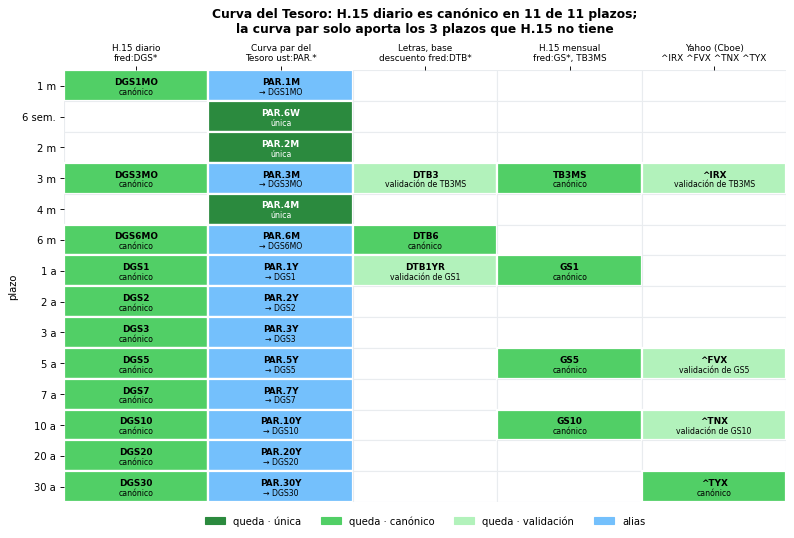

In [8]:
COLS_T = [('fred_dgs', 'H.15 diario\nfred:DGS*'), ('ust_par', 'Curva par del\nTesoro ust:PAR.*'),
          ('fred_dtb', 'Letras, base\ndescuento fred:DTB*'), ('fred_gs', 'H.15 mensual\nfred:GS*, TB3MS'),
          ('yahoo_tesoro', 'Yahoo (Cboe)\n^IRX ^FVX ^TNX ^TYX')]
ROL_TXT = {'canonico': 'canónico', 'unica': 'única', 'validacion': 'validación', 'alias': 'alias',
           'historia_previa': 'historia previa'}
pc = sel.assign(pc=plazos).dropna(subset=['pc']).copy()
pc['curva'] = pc['pc'].str[0].replace({'fred_tb': 'fred_gs'})
pc['meses'] = pc['pc'].str[1].astype(float)
tes = pc[pc['curva'].isin([c for c, _ in COLS_T])]
filas_m = sorted(tes['meses'].unique())


def etq_plazo(m):
    sem = m * 52 / 12
    if m < 12 and abs(m - round(m)) > 0.05:
        return f'{round(sem)} sem.'
    return f'{m:g} m' if m < 12 else f'{m / 12:g} a'


fig, ax = plt.subplots(figsize=(10, 6.8))
for j, (cv, _) in enumerate(COLS_T):
    for i, m in enumerate(filas_m):
        cel = tes[(tes['curva'] == cv) & (tes['meses'] == m)]
        if cel.empty:
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fc='white', ec='#e9ecef'))
            continue
        r_ = cel.iloc[0]
        ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fc=COL[r_['rol']], ec='white', lw=2))
        corto = r_['id'].split(':', 1)[1]
        if r_['rol'] == 'alias':
            sub = '→ ' + r_['alias_de'].split(':', 1)[1]
        elif r_['rol'] == 'validacion':
            sub = 'validación de ' + str(r_['canonico']).split(':', 1)[1]
        else:
            sub = ROL_TXT[r_['rol']]
        claro = r_['rol'] in ('unica', 'historia_previa')
        ax.text(j, i - .12, corto, ha='center', va='center', fontsize=8, fontweight='bold',
                color='white' if claro else 'black')
        ax.text(j, i + .2, sub, ha='center', va='center', fontsize=7, color='white' if claro else 'black')
ax.set_xlim(-.5, len(COLS_T) - .5)
ax.set_ylim(len(filas_m) - .5, -.5)
ax.set_xticks(range(len(COLS_T)), [t for _, t in COLS_T], fontsize=8)
ax.xaxis.tick_top()
ax.set_yticks(range(len(filas_m)), [etq_plazo(m) for m in filas_m])
ax.set_ylabel('plazo')
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(handles=[Patch(color=COL[k], label=ETQ[k]) for k in ['unica', 'canonico', 'validacion', 'alias']],
          loc='upper center', bbox_to_anchor=(.5, -0.01), ncol=4, frameon=False)
dgs = tes[tes['curva'] == 'fred_dgs']
par_propios = n((tes['curva'] == 'ust_par') & (tes['decision'] == 'queda'))
ax.set_title(f"Curva del Tesoro: H.15 diario es canónico en {n(dgs['rol'] == 'canonico')} de {len(dgs)} plazos;\n"
             f"la curva par solo aporta los {par_propios} plazos que H.15 no tiene", pad=34)
plt.tight_layout()
plt.show()

**Canónicos dudosos.** La regla E1 marca `canonico_dudoso` en dos casos: cuando dos fuentes empatan en nivel de fecha
y en historia (deciden la frecuencia, la fuente y, al final, el id), o cuando prefiere el mejor nivel de fecha a
costa de renunciar a más de `MARGEN_HISTORIA_DIAS` días de historia de otra serie peor fechada. **Ya están
decididos (F4):** se acepta la regla E1 (su `motivo_dudoso` empieza por «aceptado E1 (F4)») y los empates se
resolvieron a mano: los tipos del BCE y de Fama-French que empataban se quedan como únicas
(`seleccion.UNICAS_F4`) y `datahub` pasa a alias de Shiller. Uno por canónico, los de más alias primero (`n_grupo`:
el canónico y todo lo que cuelga de él); la columna `lectura` resume por qué era dudoso:

In [9]:
dud = seleccion.dudosos(sel, n=len(sel))


def lectura(m):
    pref = 'aceptado (F4): ' if m.startswith(seleccion.NOTA_DUDOSO_F4) else ''
    if 'empatan' in m:
        return pref + 'empate en nivel y en historia: lo decide el orden de E1'
    anos = [float(x) for x in re.findall(r'tiene ([\d.]+) años más', m)]
    return (pref + f'gana por mejor fecha, pero deja hasta {max(anos):.0f} años de historia de otra serie peor fechada '
            '(esa historia no se pierde: queda como alias, validación o historia previa)')


dud = dud.assign(lectura=dud['motivo_dudoso'].map(lectura))
alias_f4 = sel.loc[sel['alias_de'].isin(seleccion.DUDOSOS_RESUELTOS_F4) & (sel['fuente'] == 'datahub'), 'id'].tolist()
print(f"{len(dud)} canónicos dudosos, {n(dud['motivo_dudoso'].str.startswith(seleccion.NOTA_DUDOSO_F4))} aceptados con E1 "
      f"(F4). Empates resueltos a mano: {', '.join(seleccion.UNICAS_F4)} quedan como únicas; {', '.join(alias_f4)} es alias "
      f"de {', '.join(seleccion.DUDOSOS_RESUELTOS_F4)}. Se ven los 12 primeros; todos, en seleccion_series.csv.")
dud[['id', 'rol', 'nivel_fecha', 'pub_desde', 'n_alias', 'n_grupo', 'motivo_dudoso', 'lectura']].head(12).reset_index(drop=True)

20 canónicos dudosos, 20 aceptados con E1 (F4). Empates resueltos a mano: ecb:DFR, ecb:MRO, bis:WS_CBPOL.M.XM, ff:F3M.Mkt-RF quedan como únicas; datahub:SP500_MENSUAL es alias de shiller:P. Se ven los 12 primeros; todos, en seleccion_series.csv.


,id,rol,nivel_fecha,pub_desde,n_alias,n_grupo,motivo_dudoso,lectura
0,fred:GS10,canonico,A,1953-05-01,3,5,aceptado E1 (F4): shiller:LONGRATE tiene 82.2 años más de historia con peor nivel (C frente a A),"aceptado (F4): gana por mejor fecha, pero deja hasta 82 años de historia de otra serie peor fech..."
1,oecd:UNEMP.DEU,canonico,A,1999-03-01,3,4,aceptado E1 (F4): eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.DE tiene 7.9 años más de historia con pe...,"aceptado (F4): gana por mejor fecha, pero deja hasta 8 años de historia de otra serie peor fecha..."
2,oecd:UNEMP.FRA,canonico,A,1999-03-01,3,4,aceptado E1 (F4): eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.FR tiene 15.9 años más de historia con p...,"aceptado (F4): gana por mejor fecha, pero deja hasta 16 años de historia de otra serie peor fech..."
3,oecd:UNEMP.ITA,canonico,A,1999-03-01,3,4,aceptado E1 (F4): eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.IT tiene 15.9 años más de historia con p...,"aceptado (F4): gana por mejor fecha, pero deja hasta 16 años de historia de otra serie peor fech..."
4,oecd:UNEMP.JPN,canonico,A,1999-03-01,3,4,aceptado E1 (F4): eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.JP tiene 15.9 años más de historia con p...,"aceptado (F4): gana por mejor fecha, pero deja hasta 16 años de historia de otra serie peor fech..."
5,fred:CPIAUCSL,canonico,A,1971-02-01,2,7,aceptado E1 (F4): shiller:CPI tiene 99.9 años más de historia con peor nivel (C frente a A); gw:...,"aceptado (F4): gana por mejor fecha, pero deja hasta 100 años de historia de otra serie peor fec..."
6,oecd:CP.DEU,canonico,A,1999-03-01,2,4,aceptado E1 (F4): eurostat:HICP_EMP.DE tiene 2.0 años más de historia con peor nivel (C frente a A),"aceptado (F4): gana por mejor fecha, pero deja hasta 2 años de historia de otra serie peor fecha..."
7,oecd:CP.FRA,canonico,A,1999-03-01,2,4,aceptado E1 (F4): eurostat:HICP_EMP.FR tiene 2.0 años más de historia con peor nivel (C frente a A),"aceptado (F4): gana por mejor fecha, pero deja hasta 2 años de historia de otra serie peor fecha..."
8,oecd:CP.GBR,canonico,A,1999-03-01,2,4,aceptado E1 (F4): eurostat:HICP_EMP.UK tiene 2.0 años más de historia con peor nivel (C frente a A),"aceptado (F4): gana por mejor fecha, pero deja hasta 2 años de historia de otra serie peor fecha..."
9,oecd:CP.ITA,canonico,A,1999-03-01,2,4,aceptado E1 (F4): eurostat:HICP_EMP.IT tiene 2.0 años más de historia con peor nivel (C frente a A),"aceptado (F4): gana por mejor fecha, pero deja hasta 2 años de historia de otra serie peor fecha..."


**Historia previa (D1 manda sobre E1).** Si un alias es visible antes del corte de D1 y su canónico no, no se hace
alias: se quedan los dos, el alias con `rol = historia_previa` y `completa_a = <canónico>`. Es el caso del HICP de la
zona euro (el del BCE solo es visible por fecha de publicación desde la edición actual) y de los anuales del Banco
Mundial frente al WEO (del WEO solo hay la última edición; sus ediciones antiguas están en el paso 3b):

In [10]:
hp = sel[sel['rol'] == 'historia_previa'][['id', 'nivel_fecha', 'pub_desde', 'completa_a']]
hp = hp.merge(sel[['id', 'nivel_fecha', 'pub_desde']].rename(columns={'id': 'completa_a', 'nivel_fecha': 'nivel_canonico',
                                                                      'pub_desde': 'pub_desde_canonico'}),
              on='completa_a', how='left')
hp['años_que_aporta'] = ((pd.to_datetime(hp['pub_desde_canonico']) - pd.to_datetime(hp['pub_desde'])).dt.days / 365.25).round(1)
hp.reset_index(drop=True)

,id,nivel_fecha,pub_desde,completa_a,nivel_canonico,pub_desde_canonico,años_que_aporta
0,eurostat:HICP_EMP.EA,C,1997-03-01,ecb:HICP.M.U2.N.000000.4D0.ANR,A,2026-01-28,28.9
1,wb:CAN.NY.GDP.MKTP.KD.ZG,C,1962-12-31,imf:WEO.CAN.NGDP_RPCH,A,2026-10-13,63.8
2,wb:CHN.NY.GDP.MKTP.KD.ZG,C,1962-12-31,imf:WEO.CHN.NGDP_RPCH,A,2026-10-13,63.8
3,wb:CHN.SL.UEM.TOTL.ZS,C,1992-12-31,imf:WEO.CHN.LUR,A,2026-10-13,33.8
4,wb:JPN.NY.GDP.MKTP.KD.ZG,C,1962-12-31,imf:WEO.JPN.NGDP_RPCH,A,2026-10-13,63.8


## 4. Fiabilidad de la fecha en la lista (D2)

**Qué se ve:** el trato de la fecha de publicación de cada serie que se queda, según su veredicto en la ventana
desde 2000 (`seleccion.ventana_d2`, el mismo del `02`). **Conclusión:** ninguna serie se queda sin trato: las que no
tienen una fecha contrastada entran con una regla o un tramo conservador, que solo pueden retrasar la fecha.

- **entra sin aviso**: fecha exacta, «sin riesgo» (exacta o contrastada en toda la ventana), «fiable», «fiable con
  margen» (adelanta como mucho un margen pequeño) y «verificada sin medir» (regla verificada sin muestra para medirla);
- **entra con tramo conservador** (E5): la regla adelanta en el tramo sin contrastar;
- **entra con aviso y regla conservadora** (E4): no medible; se usa la fecha más tardía plausible según el
  calendario de la fuente, por grupo.

Las derivadas (`deriv:A-B`, calculadas a partir de otras dos) heredan el peor trato de sus componentes.

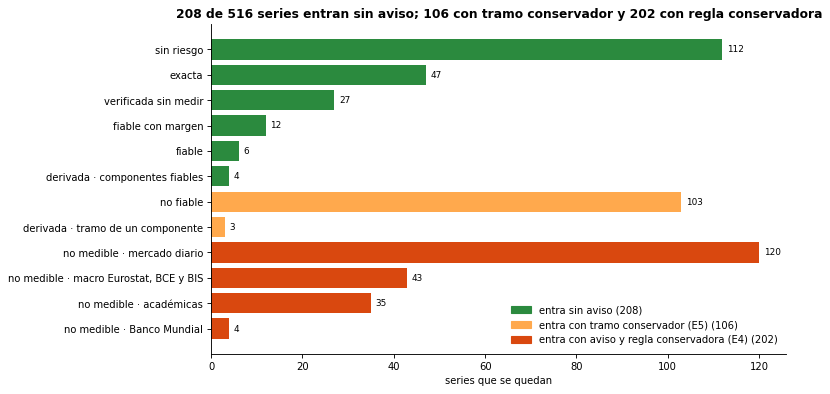

,series,con_historia_2000,historia_2000_exacta
trato,,,
entra con aviso y regla conservadora (E4),202,153,0
entra con tramo conservador (E5),106,89,0
entra sin aviso,208,148,112


In [11]:
vent = pd.Series(seleccion.ventana_d2(inv, fia).to_numpy(), index=inv['id'])
qq = sel[q].copy()
qq['ventana'] = qq['id'].map(vent)
GRUPO_TXT = {'mercado_diario': 'mercado diario', 'banco_mundial': 'Banco Mundial',
             'macro_eurostat_bce_bis': 'macro Eurostat, BCE y BIS', 'academicas': 'académicas', 'otras_fred': 'otras de FRED',
             'no_fiable': 'no fiable', 'fiable_con_margen': 'fiable con margen'}


def grupo_d2(r):
    if r['aviso_fecha'] == 'no medible':
        return 'no medible · ' + GRUPO_TXT.get(r['regla_conservadora'], str(r['regla_conservadora']))
    if r['ventana'] == 'ver componentes':
        return 'derivada · ' + ('tramo de un componente' if r['aviso_fecha'] == 'no fiable' else 'componentes fiables')
    return r['ventana']


def trato(r):
    if r['aviso_fecha'] == 'no medible':
        return 'entra con aviso y regla conservadora (E4)'
    if r['aviso_fecha'] == 'no fiable':
        return 'entra con tramo conservador (E5)'
    return 'entra sin aviso'


qq['grupo_d2'] = qq.apply(grupo_d2, axis=1)
qq['trato'] = qq.apply(trato, axis=1)
g = qq.groupby(['trato', 'grupo_d2']).size().rename('series').reset_index()
g['o'] = g['trato'].map({k: i for i, k in enumerate(COL_TRATO)})
g = g.sort_values(['o', 'series'], ascending=[False, True])
nt = qq['trato'].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(g['grupo_d2'], g['series'], color=g['trato'].map(COL_TRATO))
for y, k in enumerate(g['series']):
    ax.text(k + 1, y, str(k), va='center', fontsize=8)
ax.set_xlabel('series que se quedan')
ax.set_title(f"{nt.get('entra sin aviso', 0)} de {len(qq)} series entran sin aviso; "
             f"{nt.get('entra con tramo conservador (E5)', 0)} con tramo conservador y "
             f"{nt.get('entra con aviso y regla conservadora (E4)', 0)} con regla conservadora")
ax.legend(handles=[Patch(color=c, label=f'{k} ({nt.get(k, 0)})') for k, c in COL_TRATO.items()],
          loc='lower right', frameon=False)
plt.tight_layout()
plt.show()
qq.groupby('trato').agg(series=('id', 'size'), con_historia_2000=('desde_2000', 'sum'),
                        historia_2000_exacta=('desde_2000_exacto', 'sum'))

## 5. Cobertura temporal de lo que se queda (D1)

**Qué se ve:** por fuente, desde cuándo se ve cada serie (la **primera publicación visible**, `pub_desde`, no la
fecha de referencia) hasta su último dato. La línea fina va de la serie más antigua a la más reciente; la barra
gruesa empieza en la mediana; las líneas rojas marcan el corte de D1 y el inicio de las dos ventanas en estudio
(2007 y 2016). A la derecha: series, cuántas cumplen D1 y cuántas lo cumplen con fecha **exacta** (la fecha fiable
empieza antes del corte). **Conclusión:** casi todas las fuentes llegan al corte de D1; las que no, se quedan por
ser únicas o canónicas de su grupo.

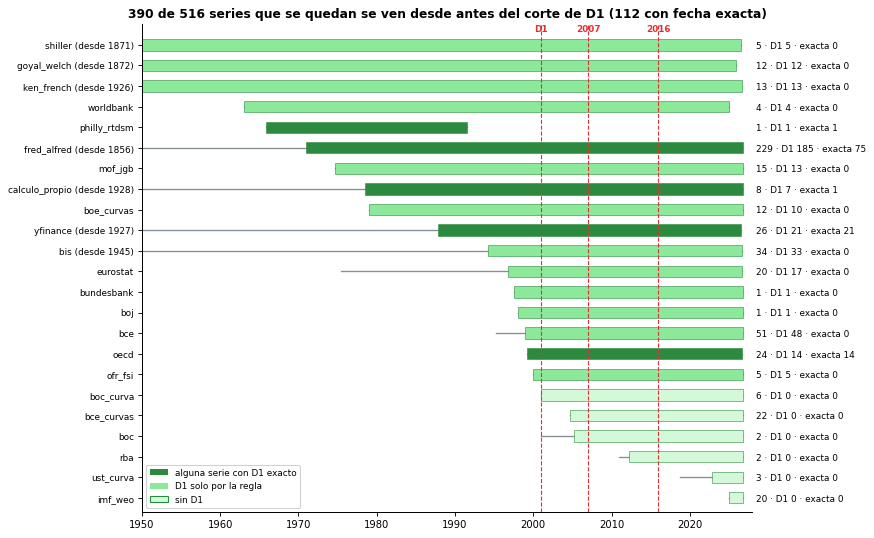

In [12]:
g = qq.merge(inv[['id', 'ref_hasta']], on='id')
g['pub'] = pd.to_datetime(g['pub_desde'])
g['fin'] = pd.to_datetime(g['ref_hasta'])
G = (g.groupby('fuente').agg(n=('id', 'size'), desde_min=('pub', 'min'), desde_med=('pub', 'median'),
                             hasta=('fin', 'max'), d1=('desde_2000', 'sum'), d1x=('desde_2000_exacto', 'sum'))
       .sort_values('desde_med', ascending=False))
X0 = pd.Timestamp('1950-01-01')
COL_D1 = {'exacto': '#2b8a3e', 'regla': '#8ce99a', 'no': '#d3f9d8'}
fig, ax = plt.subplots(figsize=(11, 6.8))
for y, (f, r_) in enumerate(G.iterrows()):
    ax.plot([max(r_['desde_min'], X0), r_['hasta']], [y, y], color='#868e96', lw=1.2, zorder=1)
    c = COL_D1['exacto'] if r_['d1x'] > 0 else (COL_D1['regla'] if r_['d1'] > 0 else COL_D1['no'])
    ax.barh(y, (r_['hasta'] - max(r_['desde_med'], X0)).days, left=max(r_['desde_med'], X0), height=0.55,
            color=c, ec='#2b8a3e', lw=.5, zorder=2)
corte = pd.Timestamp(inventario.CORTE_2000)
for x, etq in ((corte, 'D1'), (pd.Timestamp('2007-01-01'), '2007'), (pd.Timestamp('2016-01-01'), '2016')):
    ax.axvline(x, color='#e03131', ls='--', lw=1)
    ax.text(x, len(G) - .35, etq, color='#e03131', fontsize=8, ha='center', fontweight='bold')
ax.set_yticks(range(len(G)), [f + (f" (desde {r_['desde_min'].year})" if r_['desde_min'] < X0 else '')
                              for f, r_ in G.iterrows()], fontsize=8)
ax.set_xlim(X0, pd.Timestamp('2028-01-01'))
ax.set_ylim(-.7, len(G))
der = ax.twinx()
der.set_ylim(ax.get_ylim())
der.set_yticks(range(len(G)), [f"{int(r_['n'])} · D1 {int(r_['d1'])} · exacta {int(r_['d1x'])}" for _, r_ in G.iterrows()],
               fontsize=8)
der.tick_params(length=0)
der.spines[['top', 'right']].set_visible(False)
ax.set_title(f"{n(qq['desde_2000'])} de {len(qq)} series que se quedan se ven desde antes del corte de D1 "
             f"({n(qq['desde_2000_exacto'])} con fecha exacta)")
ax.legend(handles=[Patch(fc=COL_D1['exacto'], label='alguna serie con D1 exacto'),
                   Patch(fc=COL_D1['regla'], label='D1 solo por la regla'), Patch(fc=COL_D1['no'], ec='#2b8a3e', label='sin D1')],
          loc='lower left', frameon=True, framealpha=.9, fontsize=8)
plt.tight_layout()
plt.show()

## 6. EDA de las series

**Qué se ve:** las series que se quedan con alguna incidencia, por tipo y fuente; el módulo `eda` mira la forma de
cada serie (su último vintage) y las diferencias entre vintages, y **solo detecta y propone** (E7). **Conclusión:**
casi todo son saltos y rupturas para revisar a mano; los cambios de unidad confirmados se reescalan y los huecos y
las rachas solo se marcan.

Debajo de cada tipo va la propuesta por defecto para el paso 4 (`eda.PROPUESTAS`); algunas filas llevan otra
(`eda.EXCEPCIONES_PROPUESTA`): en los tipos administrados por un banco central (los tipos oficiales) y en las series
escalonadas por construcción (el libre de riesgo diario de Ken French), los escalones, los huecos y las rachas son
normales y van «sin acción».

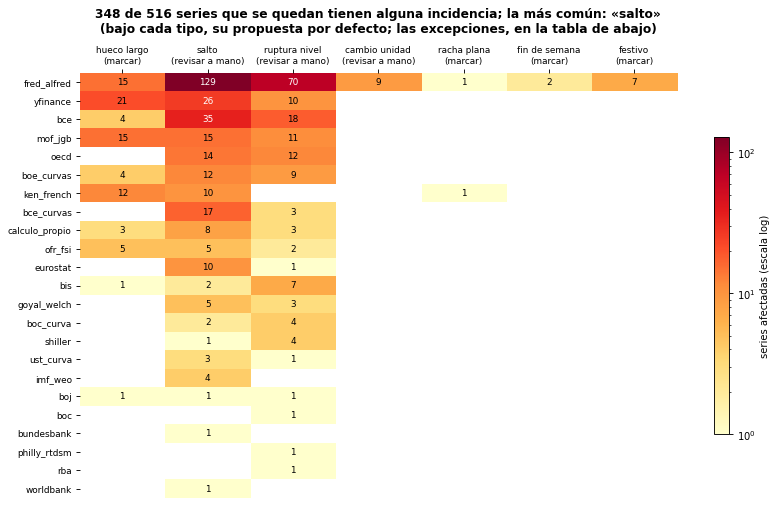

,series,eventos,propuesta,filas con otra propuesta,qué es
hueco_largo,81,658,marcar,sin acción 111,periodos seguidos sin dato (frecuencia del catálogo; diarias en días L-V)
salto,301,3986,revisar a mano,sin acción 96,cambio a más de 8 desviaciones robustas de los cambios de la serie
ruptura_nivel,162,394,revisar a mano,sin acción 31,salto de la mediana móvil (antes frente a después)
cambio_unidad,9,14,revisar a mano,"reescalar vintages anteriores 6, sin acción 3",cambio de escala entre vintages consecutivos (log10 del factor)
racha_plana,2,44,marcar,sin acción 40,posible dato congelado de la fuente: racha plana de 120 o más observaciones diarias seguidas con...
fin_de_semana,2,2,marcar,—,posible error de fecha de la fuente: cierre de mercado en fin de semana
festivo,7,52,marcar,—,posible error de fecha de la fuente: cierre de mercado en festivo


In [13]:
ids_q = set(sel.loc[q, 'id'])
eq = edas[edas['serie'].isin(ids_q)].copy()
band = eq.assign(tipo=eq['banderas'].str.split(';')).explode('tipo').dropna(subset=['tipo'])
TIPOS_S = [t for t in eda.PROPUESTAS if t in set(band['tipo'])]
hm = pd.crosstab(band['fuente'], band['tipo']).reindex(columns=TIPOS_S, fill_value=0)
hm = hm.loc[hm.sum(axis=1).sort_values(ascending=False).index]


def mapa(ax, datos, filas, cols):
    im = ax.imshow(np.where(datos > 0, datos, np.nan), cmap=CMAP_INC, norm=LogNorm(vmin=1, vmax=max(datos.max(), 2)),
                   aspect='auto')
    for i in range(datos.shape[0]):
        for j in range(datos.shape[1]):
            if datos[i, j] > 0:
                ax.text(j, i, int(datos[i, j]), ha='center', va='center', fontsize=8,
                        color='white' if np.log(datos[i, j]) > .65 * np.log(datos.max()) else 'black')
    ax.set_xticks(range(len(cols)), cols, fontsize=8)
    ax.set_yticks(range(len(filas)), filas, fontsize=8)
    for s in ax.spines.values():
        s.set_visible(False)
    return im


fig, ax = plt.subplots(figsize=(10.5, 6.4))
im = mapa(ax, hm.to_numpy().astype(float), hm.index,
          [f"{t.replace('_', ' ')}\n({eda.PROPUESTAS[t]})" for t in TIPOS_S])
ax.xaxis.tick_top()
top_s = hm.sum().idxmax()
ax.set_title(f"{len(set(band['serie']))} de {len(ids_q)} series que se quedan tienen alguna incidencia; "
             f"la más común: «{top_s.replace('_', ' ')}»\n(bajo cada tipo, su propuesta por defecto; las excepciones, "
             "en la tabla de abajo)", pad=12)
fig.colorbar(im, ax=ax, label='series afectadas (escala log)', shrink=.7)
plt.tight_layout()
plt.show()

EVENTOS_S = {'hueco_largo': 'n_huecos_largos', 'salto': 'n_saltos', 'ruptura_nivel': 'n_rupturas',
             'cambio_unidad': 'n_cambios_unidad', 'racha_plana': 'n_rachas_planas', 'fin_de_semana': 'n_fin_de_semana',
             'festivo': 'n_festivos', 'negativo_en_nivel': 'n_negativos_nivel'}
iq = incs[incs['serie'].isin(ids_q)]
otra = iq[iq['propuesta_paso4'] != iq['tipo'].map(eda.PROPUESTAS)].groupby('tipo')['propuesta_paso4'].agg(
    lambda s: ', '.join(f'{k} {v}' for k, v in s.value_counts().items()))
pd.DataFrame({'series': hm.sum(), 'eventos': [int(eq[EVENTOS_S[t]].sum()) if t in EVENTOS_S else np.nan for t in TIPOS_S],
              'propuesta': [eda.PROPUESTAS[t] for t in TIPOS_S], 'filas con otra propuesta': otra.reindex(TIPOS_S).fillna('—'),
              'qué es': [eda.NOTAS[t] for t in TIPOS_S]}, index=TIPOS_S)

**Cambios de unidad confirmados entre vintages.** Un vintage de ALFRED que cambia la escala de toda la serie (por
ejemplo, de millones a miles de millones) parece un salto enorme si se comparan vintages. Cuando el factor es una
potencia de 10 casi exacta en muchas fechas comunes, el EDA lo da por confirmado y propone **reescalar los vintages
anteriores** (`factor`: por cuánto se multiplican para casar con la unidad vigente). El borrador de preprocesado los
recoge en `escalas_por_vintage`:

In [14]:
cu = iq[iq['propuesta_paso4'] == eda.REESCALAR][['serie', 'frecuencia', 'fecha', 'tamano', 'factor', 'nota']]
cu = cu.rename(columns={'fecha': 'vintage_nuevo', 'tamano': 'log10_factor'})
cu['fechas_comunes'] = cu['nota'].str.extract(r'(\d+) fechas comunes')[0].astype(int)
esc = pd.DataFrame(PLAN['escalas_por_vintage']['series'])
igual = (set(zip(cu['serie'], cu['vintage_nuevo'], cu['factor'])) ==
         set(zip(esc['serie'], esc['antes_de_vintage'], esc['factor'])))
otros_cu = iq[(iq['tipo'] == 'cambio_unidad') & (iq['propuesta_paso4'] != eda.REESCALAR)].groupby('propuesta_paso4')['serie'].nunique()
print(f"{len(cu)} cambios de unidad confirmados; coinciden con preprocesado.yaml (escalas_por_vintage): {igual}. "
      f"Otros cambios de unidad sin reescalar, por propuesta: {otros_cu.to_dict()}")
cu.drop(columns='nota').reset_index(drop=True)

6 cambios de unidad confirmados; coinciden con preprocesado.yaml (escalas_por_vintage): True. Otros cambios de unidad sin reescalar, por propuesta: {'revisar a mano': 2, 'sin acción': 1}


,serie,frecuencia,vintage_nuevo,log10_factor,factor,fechas_comunes
0,fred:BCNSDODNS,trimestral,2026-01-09,3.0,1000.000,301
1,fred:BOGMBASE,mensual,2024-09-24,-3.0,0.001,787
2,fred:CMDEBT,trimestral,2026-01-09,3.0,1000.000,301
3,fred:REVOLSL,mensual,2025-02-07,3.0,1000.000,683
4,fred:TNWBSHNO,trimestral,2026-01-09,3.0,1000.000,301
5,fred:TOTALSL,mensual,2025-02-07,3.0,1000.000,983


**Huecos largos** (más de `eda.MIN_HUECO` periodos seguidos sin dato) de las series que se quedan, los más largos
en días. Los de tipos administrados van «sin acción» y no salen aquí. La propuesta es marcarlos: el paso 4 no rellena
nada (frecuencias nativas, huecos permanentes como nulo con aviso):

In [15]:
hl = iq[(iq['tipo'] == 'hueco_largo') & (iq['propuesta_paso4'] != eda.SIN_ACCION)].copy()
hl['dias'] = (pd.to_datetime(hl['fecha_fin']) - pd.to_datetime(hl['fecha'])).dt.days + 1
print(f"{len(hl)} huecos largos en {hl['serie'].nunique()} series que se quedan; series por frecuencia: "
      f"{hl.groupby('frecuencia')['serie'].nunique().to_dict()}. Los 12 más largos (todos, en eda_series_incidencias.csv):")
(hl.sort_values('dias', ascending=False).head(12)
   [['serie', 'fuente', 'frecuencia', 'fecha', 'fecha_fin', 'tamano', 'dias']]
   .rename(columns={'fecha': 'falta_desde', 'fecha_fin': 'falta_hasta', 'tamano': 'periodos'})
   .astype({'periodos': int}).reset_index(drop=True))

547 huecos largos en 79 series que se quedan; series por frecuencia: {'diaria': 77, 'mensual': 2}. Los 12 más largos (todos, en eda_series_incidencias.csv):


,serie,fuente,frecuencia,falta_desde,falta_hasta,periodos,dias
0,ecb:EXR.D.ISK.EUR,bce,diaria,2008-12-04,2018-01-31,2390,3346
1,fred:DGS20,fred_alfred,diaria,1987-01-01,1993-09-30,1761,2465
2,fred:DTB1YR,fred_alfred,diaria,2002-02-06,2008-06-02,1649,2309
3,bis:WS_CBPOL.M.JP,bis,mensual,2001-04-01,2006-02-01,59,1768
4,boe:NOM.20Y,boe_curvas,diaria,1980-07-18,1985-01-14,1172,1642
5,boe:NOM.25Y,boe_curvas,diaria,1992-08-28,1996-02-27,913,1279
6,bis:WS_CBPOL.M.JP,bis,mensual,2013-05-01,2016-08-01,40,1189
7,mof:JGB.1Y,mof_jgb,diaria,1978-05-22,1980-08-21,589,823
8,boe:NOM.25Y,boe_curvas,diaria,1996-06-13,1998-01-28,425,595
9,bis:WS_CBPOL.M.JP,bis,mensual,1999-03-01,2000-07-01,17,489


**Rachas planas**: muchas observaciones diarias seguidas con el mismo dato, señal de un dato congelado en la fuente.
Se excluyen los tipos administrados y las paridades fijas; el libre de riesgo diario de Ken French se cuenta, pero
«sin acción», porque repite el tipo mensual todos los días del mes:

In [16]:
rp = iq[iq['tipo'] == 'racha_plana']
(rp.groupby(['serie', 'fuente']).agg(rachas=('tipo', 'size'), racha_max_obs=('tamano', 'max'),
                                     primera=('fecha', 'min'), ultima=('fecha_fin', 'max'),
                                     propuesta=('propuesta_paso4', 'first'))
   .reset_index())

,serie,fuente,rachas,racha_max_obs,primera,ultima,propuesta
0,ff:F3D.RF,ken_french,40,5423.0,1926-07-01,2026-01-30,sin acción
1,fred:DED3,fred_alfred,4,184.0,2013-03-05,2015-12-03,marcar


## 7. EDA de los precios

**Qué se ve:** los tickers que se quedan con cada tipo de incidencia, por clase de activo (la del universo o, si no
está en él, la de Yahoo; el mismo criterio en `seleccion_precios.csv` y en `eda_precios.csv`). **Conclusión:** las
incidencias son sobre todo de calidad de Yahoo en las acciones (cierres repetidos, aperturas de relleno, sesiones
que faltan); los tickers con el historial roto se quedan con aviso como limitación declarada (F3: solo Yahoo).

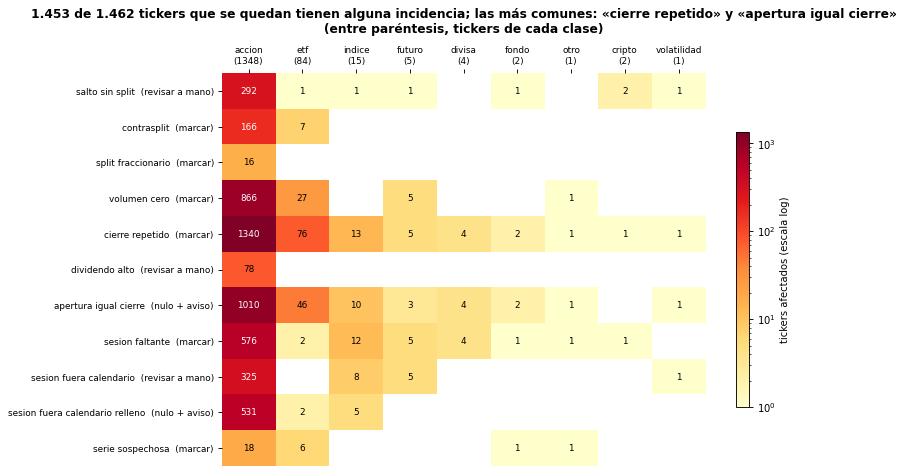

,tickers,eventos_o_sesiones,propuesta,qué es
salto_sin_split,299,2192,revisar a mano,"|Δlog close| > 0,4 sin split ni dividendo esa sesión ni la siguiente"
contrasplit,173,260,marcar,split < 1 (contrasplit)
split_fraccionario,16,16,marcar,"split > 1 no entero que no explica el precio: |log(close_t·split/close_t-1)| > 0,2"
volumen_cero,899,182330,marcar,calidad.incidencias_precios: volumen 0 en instrumento con volumen
cierre_repetido,1443,548492,marcar,calidad.incidencias_precios: cierre igual al de la sesión previa
dividendo_alto,78,183,revisar a mano,calidad.incidencias_precios: dividendo > 20 % del cierre previo
apertura_igual_cierre,1077,343650,nulo + aviso,open == close y high == low: relleno de Yahoo; no vale como apertura de t+1
sesion_faltante,602,5523,marcar,día hábil del calendario del mercado sin vela
sesion_fuera_calendario,339,2879,revisar a mano,vela en un día que el calendario del mercado da cerrado (con movimiento o volumen)
sesion_fuera_calendario_relleno,538,29534,nulo + aviso,vela de relleno en día cerrado: repite el cierre y no tiene volumen


In [17]:
CLASE = selp.set_index('id')['clase']
ip = incp[incp['ticker'].isin(set(selp.loc[qp, 'id']))].copy()
ip['clase_sel'] = ip['ticker'].map(CLASE)
TIPOS_P = [t for t in eda.PROPUESTAS if t in set(ip['tipo'])]
hp_ = pd.crosstab(ip['tipo'], ip['clase_sel'], values=ip['ticker'], aggfunc='nunique').fillna(0).reindex(TIPOS_P)
hp_ = hp_[hp_.sum().sort_values(ascending=False).index]
tot_clase = selp[qp].groupby('clase').size()

fig, ax = plt.subplots(figsize=(10.5, 6))
im = mapa(ax, hp_.to_numpy().astype(float), [f"{t.replace('_', ' ')}  ({eda.PROPUESTAS[t]})" for t in TIPOS_P],
          [f'{c}\n({tot_clase.get(c, 0)})' for c in hp_.columns])
ax.xaxis.tick_top()
top_p = hp_.sum(axis=1).sort_values(ascending=False).index[:2]
ax.set_title(f"{es(ip['ticker'].nunique())} de {es(n(qp))} tickers que se quedan tienen alguna incidencia; las más comunes: "
             f"«{top_p[0].replace('_', ' ')}» y «{top_p[1].replace('_', ' ')}»\n(entre paréntesis, tickers de cada clase)",
             pad=12)
fig.colorbar(im, ax=ax, label='tickers afectados (escala log)', shrink=.7)
plt.tight_layout()
plt.show()

eq_p = edap[edap['ticker'].isin(set(selp.loc[qp, 'id']))]
EVENTOS_P = {'volumen_cero': eq_p['volumen_cero'].sum(), 'cierre_repetido': eq_p['cierre_repetido'].sum(),
             'dividendo_alto': eq_p['dividendo_alto'].sum(), 'salto_sin_split': eq_p['saltos_sin_split'].sum(),
             'contrasplit': eq_p['contrasplits'].sum(), 'split_fraccionario': eq_p['splits_fraccionarios'].sum(),
             'sesion_faltante': eq_p['sesiones_faltantes'].sum(),
             'sesion_fuera_calendario': (eq_p['sesiones_fuera_calendario'] - eq_p['fuera_calendario_relleno']).sum(),
             'sesion_fuera_calendario_relleno': eq_p['fuera_calendario_relleno'].sum(),
             'apertura_igual_cierre': ip.loc[ip['tipo'] == 'apertura_igual_cierre', 'n'].sum(),
             'serie_sospechosa': eq_p['serie_sospechosa'].sum()}
pd.DataFrame({'tickers': hp_.sum(axis=1).astype(int), 'eventos_o_sesiones': pd.Series(EVENTOS_P).reindex(TIPOS_P).astype(int),
              'propuesta': [eda.PROPUESTAS[t] for t in TIPOS_P], 'qué es': [eda.NOTAS[t] for t in TIPOS_P]}, index=TIPOS_P)

**Tickers sospechosos.** Historial roto: más de `eda.SOSPECHA_SALTOS` saltos sin split, más de un
`eda.SOSPECHA_PCT_REPETIDO` % de cierres repetidos o más de un `eda.SOSPECHA_PCT_APERTURA` % de aperturas iguales al
cierre desde 2000. Suelen ser tickers reciclados (el mismo símbolo para otra empresa) o datos basura de Yahoo. Se
quedan **con aviso**: rehacerlos exigiría un identificador permanente (como el PERMNO de CRSP) de una fuente de pago, y
F3 decidió solo Yahoo, así que quedan como **limitación declarada** y no se descargan en el 3b:

In [18]:
sos = edap[edap['serie_sospechosa']][['ticker', 'clase', 'desde', 'hasta', 'sesiones', 'saltos_sin_split',
                                     'pct_cierre_repetido', 'pct_apertura_igual_cierre_desde_2000', 'motivo_sospecha']]
sos = sos.merge(selp[['id', 'decision', 'aviso', 'deslistado', 'truncado']], left_on='ticker', right_on='id').drop(columns='id')
print(f"{len(sos)} tickers sospechosos: {sos['decision'].value_counts().to_dict()}; con aviso en la lista: "
      f"{n(sos['aviso'].fillna('').str.contains('sospechosa'))} («{seleccion.AVISO_SOSPECHOSA}»); también deslistados: {n(sos['deslistado'])}; truncados: {n(sos['truncado'])}. "
      "Los 12 con más saltos (todos, en eda_precios.csv):")
sos.sort_values('saltos_sin_split', ascending=False).head(12).drop(columns=['decision', 'aviso']).reset_index(drop=True)

27 tickers sospechosos: {'queda': 26, 'fuera': 1}; con aviso en la lista: 27 («serie sospechosa; limitación declarada (F3)»); también deslistados: 2; truncados: 1. Los 12 con más saltos (todos, en eda_precios.csv):


,ticker,clase,desde,hasta,sesiones,saltos_sin_split,pct_cierre_repetido,pct_apertura_igual_cierre_desde_2000,motivo_sospecha,deslistado,truncado
0,MCIC,accion,1997-09-17,2026-10-12,7312,430,49.54,50.22,430 saltos sin split (> 20); 49.5 % de cierres repetidos (> 40 %); 50.2 % de aperturas iguales a...,False,False
1,DIGI,accion,2010-05-13,2026-10-12,4129,195,74.09,78.52,195 saltos sin split (> 20); 74.1 % de cierres repetidos (> 40 %); 78.5 % de aperturas iguales a...,False,False
2,CPWR,accion,2006-12-04,2026-10-12,4994,186,66.62,73.15,186 saltos sin split (> 20); 66.6 % de cierres repetidos (> 40 %); 73.2 % de aperturas iguales a...,False,False
3,COMS,accion,2008-08-15,2026-10-12,4567,137,27.94,28.51,137 saltos sin split (> 20),False,False
4,EP,accion,1999-10-27,2026-10-12,6780,117,52.09,58.84,117 saltos sin split (> 20); 52.1 % de cierres repetidos (> 40 %); 58.8 % de aperturas iguales a...,False,False
5,ULVR.L,accion,1988-07-01,2026-10-12,9816,102,2.93,0.91,102 saltos sin split (> 20),False,False
6,USBC,accion,2006-04-18,2026-10-13,5154,85,34.85,29.30,85 saltos sin split (> 20),False,False
7,032640.KS,accion,2000-04-24,2026-10-13,6611,65,8.65,2.10,65 saltos sin split (> 20),False,False
8,GR,fondo,2001-01-02,2018-02-22,4198,41,53.26,54.48,41 saltos sin split (> 20); 53.3 % de cierres repetidos (> 40 %),True,False
9,001440.KS,accion,2000-01-04,2026-10-13,6690,40,9.54,6.94,40 saltos sin split (> 20),False,False


**Apertura igual al cierre.** Una vela con `open == close` y `high == low` es relleno de Yahoo: no hubo una apertura
real ese día. Importa porque **la decisión se toma tras el cierre de t y se ejecuta a la apertura de t+1**
([convención t+1](../../../docs/tfm/arquitectura.md)): si la apertura es de relleno, el backtest ejecutaría a un precio
que no existió. Por eso la propuesta es «nulo + aviso» en esas sesiones. Distribución del % de sesiones de relleno
desde 2000, ticker a ticker (eje vertical en escala log):

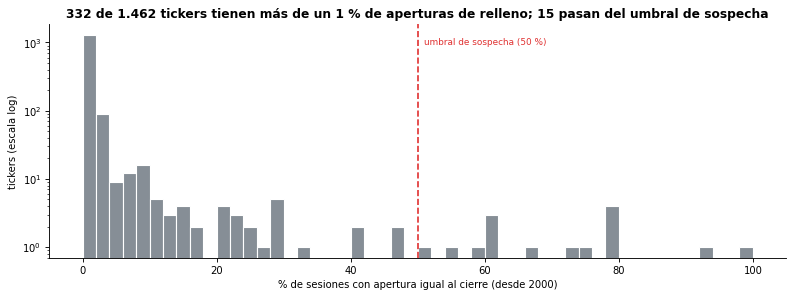

1.462 tickers que se quedan: > 0 %: 772 · > 1 %: 332 · > 5 %: 80 · > 10 %: 49 · > 50 %: 15 · mediana 0,02 %
Por clase, % medio: {'otro': 79.6, 'fondo': 77.24, 'etf': 8.51, 'divisa': 3.87, 'futuro': 2.7, 'accion': 1.33, 'indice': 0.01, 'cripto': 0.0, 'volatilidad': 0.0}


In [19]:
pct = eq_p['pct_apertura_igual_cierre_desde_2000']
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(pct, bins=np.arange(0, 102, 2), color='#868e96', edgecolor='white')
ax.set_yscale('log')
ax.axvline(eda.SOSPECHA_PCT_APERTURA, color='#e03131', ls='--')
ax.text(eda.SOSPECHA_PCT_APERTURA + 1, ax.get_ylim()[1] * .5, f'umbral de sospecha ({es(eda.SOSPECHA_PCT_APERTURA)} %)',
        color='#e03131', fontsize=8)
ax.set_xlabel('% de sesiones con apertura igual al cierre (desde 2000)')
ax.set_ylabel('tickers (escala log)')
ax.set_title(f"{n(pct > 1)} de {es(len(pct))} tickers tienen más de un 1 % de aperturas de relleno; "
             f"{n(pct > eda.SOSPECHA_PCT_APERTURA)} pasan del umbral de sospecha")
plt.tight_layout()
plt.show()
cortes = [0, 1, 5, 10, eda.SOSPECHA_PCT_APERTURA]
print(f'{es(len(pct))} tickers que se quedan: ' + ' · '.join(f'> {es(c)} %: {n(pct > c)}' for c in cortes) +
      f' · mediana {es(pct.median(), 2)} %')
print('Por clase, % medio:', eq_p.assign(c=eq_p['ticker'].map(CLASE)).groupby('c')['pct_apertura_igual_cierre_desde_2000']
      .mean().round(2).sort_values(ascending=False).to_dict())

**Velas de relleno fuera de calendario.** Velas en días que el calendario del mercado da cerrado, que repiten el
cierre anterior y no tienen volumen: Yahoo rellena así algunos festivos (la tabla dice en qué mercados y en qué
años). Propuesta: nulo + aviso. Las que sí tienen movimiento o volumen van a «revisar a mano». Los 12 mercados con
más velas (todos, en `eda_precios_incidencias.csv`):

In [20]:
rel = ip[ip['tipo'] == 'sesion_fuera_calendario_relleno']
otras = ip[ip['tipo'] == 'sesion_fuera_calendario']
(rel.groupby('mercado').agg(tickers=('ticker', 'nunique'), velas_relleno=('n', 'sum'), primera=('fecha', 'min'),
                            ultima=('fecha_fin', 'max'))
    .join(otras.groupby('mercado').agg(tickers_revisar=('ticker', 'nunique'), velas_revisar=('n', 'sum')), how='outer')
    .fillna({'tickers': 0, 'velas_relleno': 0, 'tickers_revisar': 0, 'velas_revisar': 0})
    .astype({'tickers': int, 'velas_relleno': int, 'tickers_revisar': int, 'velas_revisar': int})
    .sort_values(['velas_relleno', 'velas_revisar'], ascending=False).head(12))

,tickers,velas_relleno,primera,ultima,tickers_revisar,velas_revisar
mercado,,,,,,
XKRX,157,10072,2000-02-04,2015-08-14,106,264
XLON,86,7278,1990-04-13,2011-04-29,57,1012
XHKG,64,2145,1998-08-17,2017-08-23,18,50
XNSE,50,2133,1997-01-23,2026-01-15,51,786
XETR,38,1607,1996-12-24,2018-05-21,0,0
XSWX,16,1402,1990-04-13,2009-12-31,15,169
XPAR,38,1327,1990-04-13,2019-12-25,29,121
XMIL,35,1238,1990-04-13,2015-12-31,19,249
XMAD,34,1110,1994-08-15,2019-12-25,18,93


**Splits.** Los splits normales que explican el precio no se marcan. Sí se marcan los **contrasplits** (split < 1) y
los **splits fraccionarios** (3:2, acciones liberadas…) que no explican el movimiento del precio, y los **saltos sin
split** (más de `eda.UMBRAL_SALTO_PRECIO` en log sin split ni dividendo). Abajo, por clase, y los casos conocidos de
la sonda (`eda.CASOS_SALTO` y `eda.CASOS_SPLIT`):

In [21]:
spl = ip[ip['tipo'].isin(['contrasplit', 'split_fraccionario', 'salto_sin_split'])]
print(spl.groupby(['tipo', 'clase_sel'])['ticker'].nunique().unstack(fill_value=0).rename_axis(columns=None).to_string())
casos = edap[edap['ticker'].isin(eda.CASOS_SALTO + eda.CASOS_SPLIT)][
    ['ticker', 'clase', 'saltos_sin_split', 'contrasplits', 'splits_fraccionarios', 'banderas']]
casos.insert(1, 'caso', np.where(casos['ticker'].isin(eda.CASOS_SALTO), 'salto sin split', 'contrasplit o fraccionario'))
sin_inc = casos[(casos[['saltos_sin_split', 'contrasplits', 'splits_fraccionarios']].sum(axis=1) == 0)]['ticker'].tolist()
print('\nCasos de la sonda que hoy no dan incidencia de split (su split explica el precio):', sin_inc)
casos.sort_values(['caso', 'ticker']).reset_index(drop=True)

                    accion  cripto  etf  fondo  futuro  indice  volatilidad
tipo                                                                       
contrasplit            166       0    7      0       0       0            0
salto_sin_split        292       2    1      1       1       1            1
split_fraccionario      16       0    0      0       0       0            0

Casos de la sonda que hoy no dan incidencia de split (su split explica el precio): ['SAN.MC', 'XLF']


,ticker,caso,clase,saltos_sin_split,contrasplits,splits_fraccionarios,banderas
0,ETHA,contrasplit o fraccionario,etf,0,1,0,cierre_repetido;contrasplit
1,EWJ,contrasplit o fraccionario,etf,0,1,0,apertura_igual_cierre;cierre_repetido;contrasplit
2,SAN.MC,contrasplit o fraccionario,accion,0,0,0,apertura_igual_cierre;cierre_repetido;sesion_faltante;sesion_fuera_calendario;sesion_fuera_calen...
3,USO,contrasplit o fraccionario,etf,0,1,0,cierre_repetido;contrasplit
4,XLF,contrasplit o fraccionario,etf,0,0,0,cierre_repetido
5,AAPL,salto sin split,accion,1,0,0,apertura_igual_cierre;cierre_repetido;salto_sin_split;volumen_cero
6,ASML.AS,salto sin split,accion,1,2,0,apertura_igual_cierre;cierre_repetido;contrasplit;salto_sin_split;sesion_faltante;sesion_fuera_c...
7,CL=F,salto sin split,futuro,2,0,0,cierre_repetido;salto_sin_split;sesion_faltante;sesion_fuera_calendario;volumen_cero
8,NVDA,salto sin split,accion,1,0,0,cierre_repetido;salto_sin_split
9,SHEL.L,salto sin split,accion,1,0,0,apertura_igual_cierre;cierre_repetido;salto_sin_split;sesion_faltante;sesion_fuera_calendario;se...


## 8. Plan del preprocesado (borrador, sin aplicar)

**Qué se ve:** qué dice `config/preprocesado.yaml` y qué pasaría al aplicarlo, según la simulación
(`preprocesado_simulacion.csv`: la orden `preprocesado` aplica el plan en memoria sobre las fechas de la base y
cuenta cuántas filas cambian y cuántos días se retrasan, sin valores). **Conclusión:** el plan siempre toma la fecha
más tardía (`max`) entre la de hoy y la conservadora, así que solo retrasa; la simulación lo comprueba fila a fila
y no encuentra ninguna que se adelante.

Qué parte del plan toca a cada serie que se queda (`preprocesado.asignar_series`):

In [22]:
asig = preprocesado.asignar_series(PLAN, LISTA, inv, fia)
(asig.groupby(['seccion', 'grupo']).size().rename('series').reset_index()
     .assign(seccion=lambda d: d['seccion'].str.replace('_', ' '), grupo=lambda d: d['grupo'].map(GRUPO_TXT).fillna(d['grupo'])))

,seccion,grupo,series
0,reglas conservadoras,académicas,35
1,reglas conservadoras,Banco Mundial,4
2,reglas conservadoras,"macro Eurostat, BCE y BIS",55
3,reglas conservadoras,mercado diario,120
4,reglas conservadoras,otras de FRED,1
5,tramo no fiable,fiable con margen,3
6,tramo no fiable,no fiable,90


**Reglas conservadoras (E4), grupo a grupo.** Por grupo, cuántas reglas tiene, cuántas series y filas cambian y el
rango de los retrasos medianos; debajo, las 10 reglas que más filas mueven, con la regla de hoy, la conservadora y la
fuente que la justifica (en el repo o comprobada en la web en F1–F2). Todas las reglas, en `preprocesado.yaml` y
`preprocesado_simulacion.csv`.

El grupo que más cambia tras F1–F2 es el de las **académicas**. Ken French (`FF_MENSUAL`) pasa a **cadencia anual**
antes de que la biblioteca empezara a actualizarse cada mes: es la opción conservadora, porque nadie puede demostrar
que antes saliera cada mes (la propia web decía «al menos una vez al año»); desde entonces, mensual con margen.
Goyal-Welch pasa a la edición anual con más margen. Las cifras, debajo de la tabla por grupo:

In [23]:
FIN = {'fecha': 'fecha del dato', 'mes': 'fin de mes', 'trimestre': 'fin de trimestre', 'anio': 'fin de año'}
DIA = {'mismo': 'mismo día', 'siguiente_habil': 'hábil siguiente', 'lunes_siguiente': 'lunes siguiente'}


def txt_regla(r_):
    if not r_:
        return '—'
    if 'segmentos' in r_:
        return '; '.join((f"hasta {s['hasta']}" if s.get('hasta') else f"desde {s['desde']}") + ': ' + txt_regla(s['regla'])
                         for s in r_['segmentos'])
    if 'dia' in r_:
        return f"{r_['publicador']}: {DIA.get(r_['dia'], r_['dia'])} {r_.get('hora', '')} {r_.get('huso', '')}".strip()
    p = []
    if 'publicador' in r_:
        p.append(r_['publicador'] + (f" + {r_['lag']}" if r_.get('lag') else ' (igual)'))
    elif 'lag' in r_:
        p.append(f"{FIN.get(r_.get('fin_periodo'), r_.get('fin_periodo'))} + {r_['lag']}")
    if r_.get('habiles'):
        p.append(f"hábil {r_['habiles']}")
    if r_.get('n_habiles'):
        p.append(f"≥ {r_['n_habiles']}.º hábil")
    s = ', '.join(p)
    for t in r_.get('tramos') or []:
        s += f"; desde {t['desde']}" + (f" hasta {t['hasta']}" if t.get('hasta') else '') + f": + {t['lag']}"
    return s


filas = []
for grupo, gr in PLAN['reglas_conservadoras'].items():
    for clave, e in gr['reglas'].items():
        filas.append({'grupo': grupo, 'regla': clave, 'actual': txt_regla(e['actual']),
                      'conservadora': 'PENDIENTE: decide el usuario (sección 11)' if e.get('pendiente_calendario')
                      else txt_regla(e.get('conservadora')), 'fuente': e['fuente']})
rc = pd.DataFrame(filas).merge(sim[sim['seccion'] == 'reglas_conservadoras'][
    ['grupo', 'regla', 'n_series', 'filas_cambian', 'retraso_mediana_dias']], on=['grupo', 'regla'], how='left')
rc = rc.astype({'n_series': 'Int64', 'filas_cambian': 'Int64'})
assert len(rc) == sum(len(gr['reglas']) for gr in PLAN['reglas_conservadoras'].values())
display(rc.groupby('grupo').agg(reglas=('regla', 'size'), series=('n_series', 'sum'), filas_cambian=('filas_cambian', 'sum'),
                                retraso_mediano_min=('retraso_mediana_dias', 'min'),
                                retraso_mediano_max=('retraso_mediana_dias', 'max'))
          .rename(index=GRUPO_TXT).sort_values('filas_cambian', ascending=False))
REGLA_CONS = {k: e for gr in PLAN['reglas_conservadoras'].values() for k, e in gr['reglas'].items()}
for k in ('FF_MENSUAL', 'GW_ANUAL'):
    f_ = rc.set_index('regla').loc[k]
    print(f"{k}: {int(f_['n_series'])} series, {es(int(f_['filas_cambian']))} filas cambian, retraso mediano "
          f"{dias(f_['retraso_mediana_dias'])}. Regla: {txt_regla(REGLA_CONS[k]['conservadora'])}")
(rc.sort_values('filas_cambian', ascending=False).head(10)
   [['grupo', 'regla', 'actual', 'conservadora', 'n_series', 'filas_cambian', 'retraso_mediana_dias', 'fuente']]
   .reset_index(drop=True))

,reglas,series,filas_cambian,retraso_mediano_min,retraso_mediano_max
grupo,,,,,
mercado diario,13,120,752387,1.0,6.0
académicas,7,35,355223,2.0,449.0
"macro Eurostat, BCE y BIS",10,55,18375,4.0,31.0
Banco Mundial,1,4,230,212.0,212.0
otras de FRED,3,1,185,31.0,31.0


FF_MENSUAL: 13 series, 296.043 filas cambian, retraso mediano 449 días. Regla: hasta 2005-08-31: fin de año + 12M7D; desde 2005-09-01: fin de mes + 2M7D
GW_ANUAL: 12 series, 16.084 filas cambian, retraso mediano 183 días. Regla: fin de año + 13M; desde 2022-01-01 hasta 2022-12-31: + 15M15D


,grupo,regla,actual,conservadora,n_series,filas_cambian,retraso_mediana_dias,fuente
0,academicas,FF_MENSUAL,fin de mes + 45D,hasta 2005-08-31: fin de año + 12M7D; desde 2005-09-01: fin de mes + 2M7D,13,296043,449.0,"F1, verificado en la Wayback Machine (2026-11-19): https://web.archive.org/web/20011218003540/ht..."
1,mercado_diario,ecb_fx,ecb_fx: mismo día 16:00 Europe/Berlin,"ecb_fx + 1D, hábil target",44,263164,1.0,"publicaciones.yaml (ecb_fx: tipos de referencia hacia las 16:00 CET, días TARGET2); ficha bce (F..."
2,mercado_diario,mof_jgb,mof_jgb: hábil siguiente 08:30 Asia/Tokyo,"mof_jgb + 1D, hábil semana",15,157936,1.0,publicaciones.yaml (mof_jgb: Last-Modified 08:30 JST del hábil siguiente); ficha mof_jgb (median...
3,mercado_diario,ecb_yc,ecb_yc: hábil siguiente 12:00 Europe/Berlin,"ecb_yc + 1D, hábil target",22,124080,1.0,publicaciones.yaml (ecb_yc: Last-Modified 2026-10-13 12:00 Berlín con el dato del 12); ficha bce...
4,mercado_diario,boe_yc,boe_yc: hábil siguiente 12:00 Europe/London,"boe_yc + 1D, hábil semana",12,119811,1.0,publicaciones.yaml (boe_yc: Last-Modified del zip 2026-10-13 11:04 Londres con el dato del 12)
5,mercado_diario,boc_bonos,boc_bonos: hábil siguiente 18:00 America/Toronto,"boc_bonos + 1D, hábil semana",6,37206,1.0,"publicaciones.yaml (boc_bonos: el 2026-10-13 a las 07:44 de Toronto el último dato era el del 8,..."
6,academicas,OFR_FSI,fecha del dato + 5D,"fecha del dato + 7D, hábil us_federal",5,33880,2.0,lags.yaml (OFR_FSI: unos 2 días hábiles de retraso; el lunes 2026-07-20 el último dato era el ju...
7,academicas,GW_ANUAL,fin de año + 7M1D,fin de año + 13M; desde 2022-01-01 hasta 2022-12-31: + 15M15D,12,16084,183.0,"F2, verificado en la Wayback Machine (2026-11-19): https://web.archive.org/web/20040413082023/ht..."
8,mercado_diario,boc_valet,boc_valet: hábil siguiente 12:00 America/Toronto,"boc_valet + 1D, hábil semana",2,10989,1.0,"publicaciones.yaml (boc_valet: conservador, hábil siguiente a las 12:00 de Toronto)"
9,mercado_diario,ecb_estr,ecb_estr: hábil siguiente 08:00 Europe/Berlin,"ecb_estr + 1D, hábil target",2,7691,1.0,publicaciones.yaml (ecb_estr: el €STR de D a las 08:00 CET del hábil TARGET siguiente); ficha bc...


**Tramo no fiable (E5).** Las series con veredicto «no fiable» en la ventana desde 2000 **no se borran**: antes de su
corte (`fiable_desde`) la regla pasa a ser la actual más el adelanto máximo medido **de esa serie** más un margen fijo;
desde el corte no cambia nada. Las «fiable con margen» que adelantan alguna vez entran igual, sin margen. Las que
más se retrasan:

In [24]:
tnf = PLAN['tramo_no_fiable']
tr = pd.DataFrame([{'serie': s, **{k: v for k, v in e.items() if k != 'conservadora'},
                    'conservadora': txt_regla(e['conservadora'])} for s, e in tnf['series'].items()])
print(f"Margen: {tnf['margen_dias']} días · {len(tr)} series en el tramo: {tr['veredicto'].value_counts().to_dict()}; "
      f"adelanto medido por: {tr['medida'].value_counts().to_dict()}")
print(f"Días añadidos (dias_extra): mediana {es(tr['dias_extra'].median())}, máximo {es(tr['dias_extra'].max())}")
con_tramo = set(sel.loc[q & sel['tramo_conservador_antes_de'].notna(), 'id'])
fuera_tramo = sorted(con_tramo - set(tr['serie']))
print(f"Con tramo en la lista: {len(con_tramo)}; {len(fuera_tramo)} no entran en el tramo del plan (las derivadas se "
      f"recalculan con sus componentes; las de Eurostat con 'toda' y las de poca muestra pasan a regla conservadora): "
      f"{', '.join(fuera_tramo)}")
tr.sort_values('dias_extra', ascending=False).head(12)[
    ['serie', 'regla', 'veredicto', 'corte', 'medida', 'n', 'adelanto_dias', 'dias_extra', 'conservadora']].reset_index(drop=True)

Margen: 7 días · 93 series en el tramo: {'no fiable': 90, 'fiable con margen': 3}; adelanto medido por: {'alfred_previa': 80, 'excepciones': 12, 'regla': 1}
Días añadidos (dias_extra): mediana 24, máximo 151
Con tramo en la lista: 106; 16 no entran en el tramo del plan (las derivadas se recalculan con sus componentes; las de Eurostat con 'toda' y las de poca muestra pasan a regla conservadora): deriv:DBAA-DAAA, deriv:DBAA-DGS10, deriv:DCPF3M-DFF, eurostat:HICP_EMP.DE, eurostat:HICP_EMP.EA, eurostat:HICP_EMP.EU27_2020, eurostat:HICP_EMP.FR, eurostat:HICP_EMP.IT, eurostat:HICP_EMP.UK, eurostat:HICP_EMP.US, eurostat:ei_bssi_m_r2.M.BS-ESI-I.SA.DE, eurostat:ei_bssi_m_r2.M.BS-ESI-I.SA.EA20, eurostat:ei_bssi_m_r2.M.BS-ESI-I.SA.EU27_2020, eurostat:ei_bssi_m_r2.M.BS-ESI-I.SA.FR, eurostat:ei_bssi_m_r2.M.BS-ESI-I.SA.IT, fred:LIOR3M


,serie,regla,veredicto,corte,medida,n,adelanto_dias,dias_extra,conservadora
0,fred:MSPUS,CENSUS_VIVIENDA_NUEVA_TRIMESTRAL,no fiable,2011-04-25,alfred_previa,61,144.0,151,fin de trimestre + 1M152D
1,fred:BBKMGDP,CHICAGO_BBK,no fiable,2021-05-04,alfred_previa,66,96.0,103,fin de mes + 2M104D
2,fred:FRBKCLMCILA,KC_LMCI,no fiable,2014-11-14,alfred_previa,142,73.0,80,fin de mes + 1M81D
3,fred:FRBKCLMCIM,KC_LMCI,no fiable,2014-11-14,alfred_previa,142,73.0,80,fin de mes + 1M81D
4,fred:MSACSR,CENSUS_VIVIENDA_NUEVA,no fiable,2011-05-24,alfred_previa,184,73.0,80,fin de mes + 1M81D
5,fred:EXPINF1YR,CLEVELAND_EXPINF,no fiable,2021-10-14,alfred_previa,59,71.0,78,fin de mes + 79D
6,fred:EXPINF10YR,CLEVELAND_EXPINF,no fiable,2021-10-14,alfred_previa,59,71.0,78,fin de mes + 79D
7,fred:PCETRIM12M159SFRBDAL,BEA_RENTA_GASTO,no fiable,2005-09-01,alfred_previa,254,59.0,66,fin de mes + 1M67D
8,fred:CFNAIMA3,CFNAIMA3,no fiable,2011-05-23,alfred_previa,184,56.0,63,fin de mes + 1M64D
9,fred:CFNAI,CFNAI,no fiable,2011-05-23,alfred_previa,184,56.0,63,fin de mes + 1M64D


**Series reconstruidas hacia atrás.** Un índice creado en una fecha (`publicado_desde`) no existía antes, aunque hoy
traiga valores desde mucho antes (la metodología recalculada hacia atrás). Sus filas anteriores pasan a
`publicado_desde`. Son el NFCI y sus componentes, la regla de Sahm y el STLFSI4 (del catálogo) y, desde F2, las
fechas de creación comprobadas en la web (`reconstruidas.externas`: Ken French, OFR FSI, Goyal-Welch y BIS; detalle
en la sección 11). Y **H.15 diario antiguo**
(`h15_diario`): el archivo de la Fed solo guarda la edición semanal de H.15 antes de `h15_diario.hasta`, así que las
diarias del publicador `fed_h15` se retrasan en ese tramo lo que tarda la edición semanal (regla impresa abajo).
Debajo, la simulación de estas secciones y de las otras dos (escalas por vintage y proyecciones, que no cambian
fechas):

In [25]:
rec = pd.Series(PLAN['reconstruidas']['series'], name='publicado_desde').rename_axis('serie').reset_index()
print(rec.to_string(index=False))
print('Nota del plan:', PLAN['reconstruidas']['notas'][0])
print(f"Externas (F2): {len(EXT)} patrones con publicado_desde comprobado en la web (sección 11).")
h15 = PLAN['h15_diario']
print(f"\nH.15 diario: publicador {h15['publicador']}, filas publicadas antes de {h15['hasta']}, regla "
      f"{txt_regla(h15['conservadora'])}.")
(sim[sim['seccion'].isin(['reconstruidas', 'h15_diario', 'escalas_por_vintage', 'proyecciones'])][
    ['seccion', 'n_series', 'filas_regla', 'filas_cambian', 'retraso_mediana_dias', 'retraso_p95_dias', 'retraso_max_dias']]
    .astype({'filas_cambian': 'Int64', 'retraso_mediana_dias': 'Int64', 'retraso_p95_dias': 'Int64',
             'retraso_max_dias': 'Int64'}).reset_index(drop=True))

            serie publicado_desde
       fred:ANFCI      2011-05-25
        fred:NFCI      2011-05-25
  fred:NFCICREDIT      2012-07-05
fred:NFCILEVERAGE      2012-07-05
    fred:NFCIRISK      2012-07-05
 fred:SAHMCURRENT      2019-09-06
fred:SAHMREALTIME      2019-09-06
     fred:STLFSI4      2022-11-10
Nota del plan: fred:STLFSI4: publicado_desde 2022-11-10 (versión 4 del índice): las filas anteriores son la metodología nueva recalculada hacia atrás
Externas (F2): 10 patrones con publicado_desde comprobado en la web (sección 11).

H.15 diario: publicador fed_h15, filas publicadas antes de 2005-06-28, regla fed_h15 + 7D.


,seccion,n_series,filas_regla,filas_cambian,retraso_mediana_dias,retraso_p95_dias,retraso_max_dias
0,h15_diario,18,134433,134433,7,7,7
1,reconstruidas,55,280506,280506,12461,26926,48102
2,escalas_por_vintage,6,49143,0,<NA>,<NA>,<NA>
3,proyecciones,243,365,0,<NA>,<NA>,<NA>


**Escalas por vintage**: los cambios de unidad confirmados de la sección 6 (los vintages anteriores se multiplican
por el factor para llevarlos a la unidad vigente). La simulación no cambia fechas por ellos; solo cuenta las filas:

In [26]:
print(PLAN['escalas_por_vintage']['criterio'])
pd.DataFrame(PLAN['escalas_por_vintage']['series'])

log10 del factor entero = ±3, al menos 20 fechas comunes, sin declarar en el catálogo (unidad_por_vintage) y serie que se queda (preprocesado.propuesta_escalas_vintage; los tests comprueban que coincide)


,serie,antes_de_vintage,factor,comunes
0,fred:BCNSDODNS,2026-01-09,1000.000,301
1,fred:BOGMBASE,2024-09-24,0.001,787
2,fred:CMDEBT,2026-01-09,1000.000,301
3,fred:REVOLSL,2025-02-07,1000.000,683
4,fred:TNWBSHNO,2026-01-09,1000.000,301
5,fred:TOTALSL,2025-02-07,1000.000,983


**Cuánto se retrasan las fechas, por grupo.** Cada punto es una regla de la simulación (su retraso mediano en días);
la caja resume las reglas del grupo y la cruz roja es el mayor retraso de cualquier fila del grupo. Escala log: el
mercado diario se mueve un día; las reconstruidas, años.

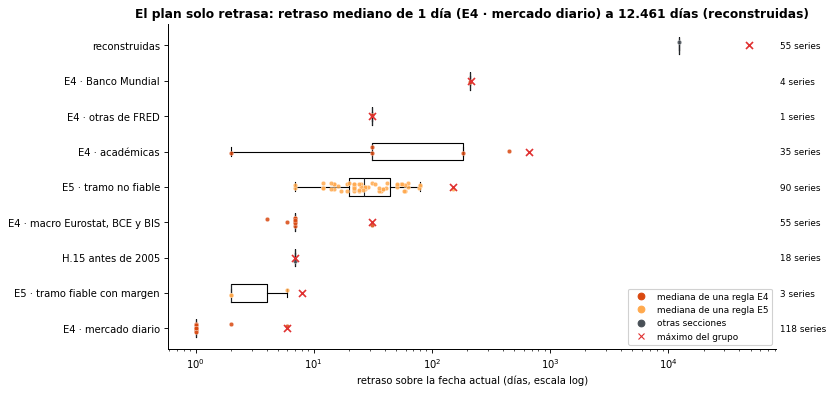

In [27]:
s2 = sim[sim['filas_cambian'].fillna(0) > 0].copy()
h15_txt = f"H.15 antes de {PLAN['h15_diario']['hasta'][:4]}"
s2['g'] = np.select([s2['seccion'] == 'reglas_conservadoras', s2['seccion'] == 'tramo_no_fiable'],
                    ['E4 · ' + s2['grupo'].map(GRUPO_TXT).fillna(s2['grupo']), 'E5 · tramo ' + s2['grupo'].str.replace('_', ' ')],
                    s2['seccion'].map({'h15_diario': h15_txt, 'reconstruidas': 'reconstruidas'}))
med = s2.groupby('g')['retraso_mediana_dias'].median().sort_values()
orden = med.index
COL_G = lambda k: (COL_TRATO['entra con aviso y regla conservadora (E4)'] if k.startswith('E4')
                   else COL_TRATO['entra con tramo conservador (E5)'] if k.startswith('E5') else '#495057')
fig, ax = plt.subplots(figsize=(10.5, 5))
datos = [s2.loc[s2['g'] == k, 'retraso_mediana_dias'].to_numpy() for k in orden]
ax.boxplot(datos, vert=False, widths=.5, showfliers=False, medianprops={'color': '#212529'})
for i, (k, d) in enumerate(zip(orden, datos), start=1):
    ax.scatter(d, np.full(len(d), i) + np.random.default_rng(i).uniform(-.12, .12, len(d)), s=16, color=COL_G(k),
               alpha=.85, zorder=3, ec='white', lw=.3)
    ax.scatter([s2.loc[s2['g'] == k, 'retraso_max_dias'].max()], [i], marker='x', color='#e03131', s=40, zorder=4)
ax.set_yticks(range(1, len(orden) + 1), orden)
ax.set_ylim(.4, len(orden) + .6)
ax.set_xscale('log')
ax.set_xlabel('retraso sobre la fecha actual (días, escala log)')
der = ax.twinx()
der.set_ylim(ax.get_ylim())
der.set_yticks(range(1, len(orden) + 1), [f"{int(s2.loc[s2['g'] == k, 'n_series'].sum())} series" for k in orden], fontsize=8)
der.tick_params(length=0)
der.spines[['top', 'right']].set_visible(False)
ax.set_title(f"El plan solo retrasa: retraso mediano de {dias(med.iloc[0])} ({orden[0]}) "
             f"a {dias(med.iloc[-1])} ({orden[-1]})")
ax.legend(handles=[plt.Line2D([], [], marker='o', ls='', color=COL_G('E4'), label='mediana de una regla E4'),
                   plt.Line2D([], [], marker='o', ls='', color=COL_G('E5'), label='mediana de una regla E5'),
                   plt.Line2D([], [], marker='o', ls='', color=COL_G('x'), label='otras secciones'),
                   plt.Line2D([], [], marker='x', ls='', color='#e03131', label='máximo del grupo')],
          loc='lower right', frameon=True, framealpha=.9, fontsize=8)
plt.tight_layout()
plt.show()

**Las verificaciones de la simulación** (fila `total` de `preprocesado_simulacion.csv`). Si alguna no es cero, el
plan está mal: una fila adelantaría su fecha (vería el futuro), su `disponible_utc` (el instante en que el dato se
puede usar) no casaría con la fecha nueva o dos vintages de un mismo dato quedarían en orden inverso.

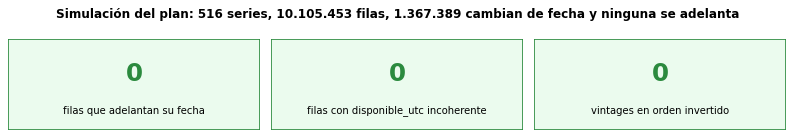

Filas paradas por el tope del primer vintage de ALFRED (no pasan de él): 108


In [28]:
VER = [('filas_adelantan', 'filas que adelantan su fecha'), ('filas_disponible_incoherente', 'filas con disponible_utc incoherente'),
       ('filas_orden_roto', 'vintages en orden invertido')]
fig, axs = plt.subplots(1, 3, figsize=(10, 1.7))
for ax, (col, etq) in zip(axs, VER):
    k = int(tot[col])
    ok = k == 0
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, fc='#ebfbee' if ok else '#fff5f5', ec='#2b8a3e' if ok else '#e03131', lw=1.5,
                               transform=ax.transAxes))
    ax.text(.5, .62, f'{k}', ha='center', va='center', fontsize=22, fontweight='bold',
            color='#2b8a3e' if ok else '#e03131', transform=ax.transAxes)
    ax.text(.5, .22, etq, ha='center', va='center', fontsize=9, transform=ax.transAxes)
    ax.axis('off')
fig.suptitle(f"Simulación del plan: {int(tot['n_series'])} series, {es(int(tot['filas_regla']))} filas, "
             f"{es(int(tot['filas_cambian']))} cambian de fecha y ninguna se adelanta", fontweight='bold')
plt.tight_layout()
plt.show()
print(f"Filas paradas por el tope del primer vintage de ALFRED (no pasan de él): {int(tot['filas_con_tope'])}")

## 9. Lo que falta por descargar (paso 3b)

**Qué se ve:** `descargas_3b.csv` por tipo, separando lo **pendiente** (por prioridad) de lo que **no se descarga**
por limitación declarada (columna `estado`). **Conclusión:** lo urgente (prioridad alta) es el refresco de lo que se
queda, las ediciones antiguas del WEO, el archivo de las OAS de ICE y los instrumentos invertibles desde la UE; lo
que dependía de una fuente de pago (deslistados, sospechosos, aperturas, supervivencia) ya no se descarga: F3
decidió solo Yahoo y queda como limitación declarada.

La lista junta: instrumentos del universo sin fichero de precios; ediciones antiguas del WEO (para que el WEO tenga
historia visible; traen también sus previsiones, que van a la tabla de proyecciones); agregados de D3 que hoy no
están; el archivo periódico de las OAS de ICE (diferenciales de crédito; FRED solo guarda una ventana móvil); el
refresco hasta hoy de las series que se quedan (los alias no se refrescan) y de los precios; las re-descargas de
ficheros truncados, y las deudas del README.

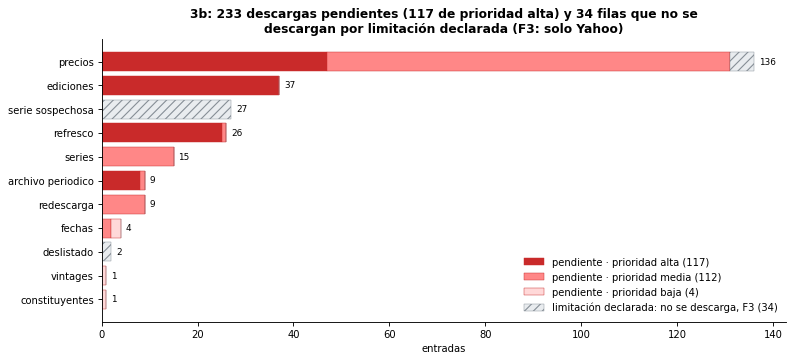

,pendientes,alta,media,baja,limitacion_declarada,ejemplos
tipo,,,,,,
precios,131,47,84,0,5,"yf:ABTC.SW, yf:AETH.SW, yf:CNDX.L"
ediciones,37,37,0,0,0,"imf_weo:edicion:2008-04, imf_weo:edicion:2008-10, imf_weo:edicion:2009-04"
refresco,26,25,1,0,0,"refresco:bce, refresco:bce_curvas, refresco:bis"
series,15,0,15,0,0,"boc:historia_pre2001, eurostat:ei_bssi_m_r2.EA, eurostat:une_rt_m.EA"
archivo_periodico,9,8,1,0,0,"fred:BAMLC0A0CM, fred:BAMLC0A0CMEY, fred:BAMLC0A1CAAA"
redescarga,9,0,9,0,0,"AT, AVB, BLY"
fechas,4,0,2,2,0,"fred:h15_diario_pre2005, ken_french:ediciones_antiguas, academicas:reglas_sin_verificar"
constituyentes,1,0,0,1,0,constituyentes:nikkei225_ibovespa
vintages,1,0,0,1,0,vintages:bce_eurostat_bis_bm


In [29]:
PRIO = ['alta', 'media', 'baja']
NO_DESC = 'no se descarga'
COL_P3 = {**COL_P, NO_DESC: '#e9ecef'}
d3g = d3b.assign(cat=np.where(d3b['estado'] == 'pendiente', d3b['prioridad'], NO_DESC))
CATS = PRIO + [NO_DESC]
ctp = pd.crosstab(d3g['tipo'], d3g['cat']).reindex(columns=CATS, fill_value=0)
ctp = ctp.loc[ctp.sum(axis=1).sort_values().index]
cuenta3 = d3g['cat'].value_counts()
fig, ax = plt.subplots(figsize=(10, 4.6))
izq = np.zeros(len(ctp))
for c in CATS:
    ax.barh(ctp.index.str.replace('_', ' '), ctp[c], left=izq, color=COL_P3[c],
            ec='#c92a2a' if c in PRIO else '#868e96', lw=.4, hatch='///' if c == NO_DESC else None,
            label=(f'pendiente · prioridad {c} ({cuenta3.get(c, 0)})' if c in PRIO
                   else f'limitación declarada: no se descarga, F3 ({cuenta3.get(c, 0)})'))
    izq += ctp[c].to_numpy()
for y, k in enumerate(ctp.sum(axis=1)):
    ax.text(k + 1, y, str(k), va='center', fontsize=8)
ax.set_xlabel('entradas')
ax.set_title(f"3b: {len(pend3b)} descargas pendientes ({pr3b['alta']} de prioridad alta) y {len(lim3b)} filas que no se\n"
             "descargan por limitación declarada (F3: solo Yahoo)")
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()
(d3b.groupby('tipo')
    .agg(pendientes=('estado', lambda s: n(s == 'pendiente')),
         alta=('prioridad', lambda s: n(s == 'alta')), media=('prioridad', lambda s: n(s == 'media')),
         baja=('prioridad', lambda s: n(s == 'baja')),
         limitacion_declarada=('estado', lambda s: n(s == 'limitacion_declarada')),
         ejemplos=('id', lambda s: ', '.join(s.head(3))))
    .sort_values(['pendientes', 'limitacion_declarada'], ascending=False))

In [30]:
pu = d3b[(d3b['tipo'] == 'precios') & d3b['motivo'].str.contains('instrumento del universo')]
print(f"Instrumentos del universo sin precios: {len(pu)} ({n(pu['estado'] == 'pendiente')} pendientes, "
      f"{n(pu['estado'] == 'limitacion_declarada')} en limitación declarada; invertibles para un minorista de la UE: "
      f"{n(pu['detalle'] == 'invertible minorista UE')})")
print(pu[pu['estado'] == 'pendiente'].groupby(['clase', 'prioridad']).size().unstack(fill_value=0)
      .rename_axis(index=None, columns=None).to_string())
print(f"\nLimitación declarada (F3): «{seleccion.MOTIVO_F3}»")
lim_txt = lim3b.assign(que=lim3b['motivo'].str.split(' · ').str[-1])
print(lim3b['tipo'].value_counts().to_string())
print('Deslistados:', ', '.join(lim3b.loc[lim3b['tipo'] == 'deslistado', 'id']),
      '· otros:', ', '.join(lim3b.loc[~lim3b['tipo'].isin(['deslistado', 'serie_sospechosa']), 'id']))
print('Redescargas (truncados, pendientes):', ', '.join(d3b.loc[d3b['tipo'] == 'redescarga', 'id']))
rf = pend3b[pend3b['tipo'] == 'refresco']
rf_s = rf[~rf['id'].str.contains(':precios:|:proyecciones:')]
print(f"\nRefresco de series (solo lo que se queda): {len(rf_s)} fuentes, "
      f"{rf_s['detalle'].str.extract(r'(\d+)')[0].astype(int).sum()} series. Aparte: "
      + '; '.join(f"{i.split(':', 1)[1]} {d}" for i, d in rf.loc[~rf.index.isin(rf_s.index), ['id', 'detalle']]
                  .itertuples(index=False)))

Instrumentos del universo sin precios: 132 (130 pendientes, 2 en limitación declarada; invertibles para un minorista de la UE: 47)
             alta  media
divisa          0      6
etf            40     53
etp             7      0
futuro          0     13
indice          0      7
volatilidad     0      4

Limitación declarada (F3): «solo Yahoo (F3): limitación declarada; sesgo de supervivencia medido en la sonda»
tipo
serie_sospechosa    27
precios              5
deslistado           2
Deslistados: DWD, GR · otros: precios:aperturas, supervivencia:salidos_sin_precio, supervivencia:sp500_quiebras_q, yf:AIGA.L, yf:^V2TX
Redescargas (truncados, pendientes): AT, AVB, BLY, EA, EQR, LEG, PSKY, QRVO, WBD

Refresco de series (solo lo que se queda): 23 fuentes, 516 series. Aparte: precios:coinbase 2 ficheros; precios:yahoo 1460 ficheros; proyecciones:fred_alfred 3 proyecciones


## 10. Fronteras con otros temas (E6 y F5)

**Qué se ve:** las series y tickers que podían solaparse con los compañeros. **Conclusión (F5):** lo numérico se
queda en el Tema 1 y los textos e informes van a los otros temas; falta confirmarlo con los compañeros, pero no
bloquea el paso 4.

- **Tema 2** (bancos centrales y riesgo sistémico): las series numéricas del BCE y del BIS se quedan aquí; los textos,
  allí;
- **Tema 3** (empresas): los precios de las acciones, aquí; los informes, allí, con la misma lista de empresas;
- **Tema 4** (noticias y alternativos): SKEW, el ESI y UMCSENT se quedan aquí; los textos, allí.

In [31]:
fr = sel[sel['frontera'].notna()]
print('Series por tema y decisión:')
print(pd.crosstab(fr['frontera'], fr['decision']).rename_axis(index=None, columns=None).to_string())
print('\nTickers por tema y decisión:')
print(pd.crosstab(selp['frontera'].fillna('sin frontera'), selp['decision']).rename_axis(index=None, columns=None).to_string())
(fr[fr['decision'] == 'queda'].groupby(['frontera', 'fuente'])['id']
   .agg(series='size', ejemplos=lambda s: ', '.join(s.head(3))).reset_index())

Series por tema y decisión:
       alias  queda
tema2      2    120
tema4      1      7

Tickers por tema y decisión:
              fuera  queda
sin frontera      2    114
tema3             7   1348


,frontera,fuente,series,ejemplos
0,tema2,bce,51,"ecb:DFR, ecb:EONIA, ecb:ESTR"
1,tema2,bce_curvas,22,"ecb:YC.AAA.10Y, ecb:YC.AAA.15Y, ecb:YC.AAA.1Y"
2,tema2,bis,34,"bis:WS_CBPOL.M.CA, bis:WS_CBPOL.M.CN, bis:WS_CBPOL.M.DE"
3,tema2,fred_alfred,8,"fred:ANFCI, fred:CFSI, fred:KCFSI"
4,tema2,ofr_fsi,5,"ofr:FSI, ofr:FSI_CREDIT, ofr:FSI_FUNDING"
5,tema4,eurostat,5,"eurostat:ei_bssi_m_r2.M.BS-ESI-I.SA.DE, eurostat:ei_bssi_m_r2.M.BS-ESI-I.SA.EA20, eurostat:ei_bs..."
6,tema4,fred_alfred,1,fred:UMCSENT
7,tema4,yfinance,1,yf:^SKEW


## 11. Decisiones tomadas y lo que queda

**Qué se ve:** las decisiones de cierre F1–F5 del usuario (detalle en el
[plan](../../../docs/fase2/mercados_series/PLAN_DESCARGA.md), «Decisiones de cierre del paso 3») y su efecto, medido
aquí; debajo, las fechas de creación comprobadas en la web. **Conclusión:** todas las fechas que usa el plan están
verificadas o son conservadoras; solo falta confirmar las fronteras con los compañeros y lanzar el 3b.

Para medir F1 y F2 esta celda lee de la base **solo las columnas de fechas** (`preprocesado._leer_base_fechas`, sin
valores) de las series afectadas y les aplica el plan con `preprocesado.fechas_curadas`, igual que la simulación.

In [32]:
import fnmatch

ids_queda = set(sel.loc[q, 'id'])
ids_ext = {p_: sorted(s for s in ids_queda if fnmatch.fnmatch(s, p_)) for p_ in EXT}
ids_ff = set(asig.loc[asig['regla'] == 'FF_MENSUAL', 'id'])
bf = preprocesado._leer_base_fechas(set().union(*ids_ext.values()) | ids_ff)
assert 'valor' not in bf.columns                                   # solo fechas
bf = bf[bf['serie'].astype(str).isin(ids_queda)].reset_index(drop=True)
cur = preprocesado.fechas_curadas(bf, PLAN, asig)
pub = bf['fecha_publicacion'].to_numpy(dtype='datetime64[ns]')
ret = (cur['fecha_publicacion_curada'].to_numpy(dtype='datetime64[ns]') - pub) / np.timedelta64(1, 'D')
ret1 = (cur['fecha_capa1'].to_numpy(dtype='datetime64[ns]') - pub) / np.timedelta64(1, 'D')
serie_bf = bf['serie'].astype(str).to_numpy()
recons = cur['reconstruida'].to_numpy(dtype=bool)


def med(x):
    x = x[x > 0]
    return dias(float(np.median(x))) if len(x) else '—'


# F1: Ken French por periodo de referencia (capa 1, la regla conservadora)
seg = REGLA_CONS['FF_MENSUAL']['conservadora']['segmentos']
corte_ff = np.datetime64(seg[0]['hasta'])
es_ff = (cur['regla'] == 'FF_MENSUAL').to_numpy()
ref = bf['fecha_referencia'].to_numpy(dtype='datetime64[ns]')
ff_a, ff_d = es_ff & (ref <= corte_ff), es_ff & (ref > corte_ff)
# F2: filas que cambian por la capa de reconstruidas en las series de `externas`
m_ext = recons & np.isin(serie_bf, list(set().union(*ids_ext.values())))
# F4
alias_f4 = sel.loc[sel['alias_de'].isin(seleccion.DUDOSOS_RESUELTOS_F4) & (sel['fuente'] == 'datahub'), 'id'].tolist()
F = [
    ('F1', 'Ken French antes de las ediciones archivadas: cadencia anual, verificada en la web',
     f"hasta {seg[0]['hasta']} ({txt_regla(seg[0]['regla'])}): {es(n(ff_a))} filas, retraso mediano {med(ret1[ff_a])}; "
     f"después ({txt_regla(seg[1]['regla'])}): {es(n(ff_d))} filas, {med(ret1[ff_d])}"),
    ('F2', 'Fecha de creación (Ken French, OFR FSI, Goyal-Welch, BIS) a publicado_desde, comprobada en la web',
     f"{len(EXT)} fechas; {len(set(serie_bf[m_ext]))} series que se quedan; {es(n(m_ext & (ret > 0)))} filas cambian "
     f"por `externas` (retraso mediano {med(ret[m_ext])})"),
    ('F3', 'Q1 = solo Yahoo; lo que falta es limitación declarada',
     f"3b: {len(pend3b)} pendientes y {len(lim3b)} sin descargar ({', '.join(f'{k} {v}' for k, v in lim3b['tipo'].value_counts().items())}); "
     f"{n_sos} tickers sospechosos con aviso"),
    ('F4', 'Canónicos dudosos: se acepta E1; empates a mano',
     f"{len(seleccion.UNICAS_F4)} series pasan a únicas; {', '.join(alias_f4)} es alias de "
     f"{', '.join(seleccion.DUDOSOS_RESUELTOS_F4)}; {n(dud['motivo_dudoso'].str.startswith(seleccion.NOTA_DUDOSO_F4))} "
     "dudosos aceptados"),
    ('F5', 'Fronteras: lo numérico, en el Tema 1; textos e informes, en los Temas 2, 3 y 4',
     f"se quedan aquí tema2 {n(q & (sel['frontera'] == 'tema2'))} y tema4 {n(q & (sel['frontera'] == 'tema4'))} series y "
     f"tema3 {n(qp & (selp['frontera'] == 'tema3'))} tickers; falta confirmarlo con los compañeros"),
]
display(pd.DataFrame(F, columns=['#', 'decisión', 'efecto']).style.hide(axis='index'))

#,decisión,efecto
F1,"Ken French antes de las ediciones archivadas: cadencia anual, verificada en la web","hasta 2005-08-31 (fin de año + 12M7D): 246.269 filas, retraso mediano 481 días; después (fin de mes + 2M7D): 64.496 filas, 23 días"
F2,"Fecha de creación (Ken French, OFR FSI, Goyal-Welch, BIS) a publicado_desde, comprobada en la web",10 fechas; 47 series que se quedan; 267.273 filas cambian por `externas` (retraso mediano 12.986 días)
F3,Q1 = solo Yahoo; lo que falta es limitación declarada,"3b: 233 pendientes y 34 sin descargar (serie_sospechosa 27, precios 5, deslistado 2); 26 tickers sospechosos con aviso"
F4,Canónicos dudosos: se acepta E1; empates a mano,4 series pasan a únicas; datahub:SP500_MENSUAL es alias de shiller:P; 20 dudosos aceptados
F5,"Fronteras: lo numérico, en el Tema 1; textos e informes, en los Temas 2, 3 y 4",se quedan aquí tema2 120 y tema4 7 series y tema3 1348 tickers; falta confirmarlo con los compañeros


**Fechas comprobadas en la web** (`reconstruidas.externas` de `preprocesado.yaml`): desde cuándo existe cada conjunto
de datos (antes no se puede ver nada), con qué cadencia se fecha después (la regla conservadora de sus series) y la
fuente que lo prueba (la primera URL que cita el YAML):

In [33]:
regla_de = asig.drop_duplicates('id').set_index('id')['regla']


def cadencia(ids):
    reglas = sorted({regla_de[s] for s in ids if s in regla_de.index})
    return '; '.join(f"{k}: {txt_regla(REGLA_CONS[k]['conservadora'])}" for k in reglas if k in REGLA_CONS) or '—'


pd.DataFrame([{'conjunto': p_, 'publicado_desde': e['publicado_desde'], 'series que se quedan': len(ids_ext[p_]),
               'cadencia después': cadencia(ids_ext[p_]),
               'fuente': re.search(r'https?://\S+', e['fuente']).group(0)}
              for p_, e in sorted(EXT.items(), key=lambda kv: kv[1]['publicado_desde'])]).style.hide(axis='index')

conjunto,publicado_desde,series que se quedan,cadencia después,fuente
ff:F3M.*,2001-12-18,1,FF_MENSUAL: hasta 2005-08-31: fin de año + 12M7D; desde 2005-09-01: fin de mes + 2M7D,https://web.archive.org/web/20011218003540/http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html
ff:F3D.*,2002-06-04,4,FF_MENSUAL: hasta 2005-08-31: fin de año + 12M7D; desde 2005-09-01: fin de mes + 2M7D,https://web.archive.org/web/20011218003540/http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html
gw:*,2004-04-13,12,GW_ANUAL: fin de año + 13M; desde 2022-01-01 hasta 2022-12-31: + 15M15D,https://web.archive.org/web/20040413082023/http://www.bus.emory.edu:80/AGoyal/
ff:MOMD.*,2005-07-26,1,FF_MENSUAL: hasta 2005-08-31: fin de año + 12M7D; desde 2005-09-01: fin de mes + 2M7D,http://web.archive.org/web/20050726075154/http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html
ff:IND5D.*,2005-07-26,5,FF_MENSUAL: hasta 2005-08-31: fin de año + 12M7D; desde 2005-09-01: fin de mes + 2M7D,http://web.archive.org/web/20050726075154/http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html
ff:F5M.*,2014-12-19,0,—,https://web.archive.org/web/20011218003540/http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html
ff:F5D.*,2015-06-01,2,FF_MENSUAL: hasta 2005-08-31: fin de año + 12M7D; desde 2005-09-01: fin de mes + 2M7D,https://web.archive.org/web/20011218003540/http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html
bis:WS_DSR.*,2015-09-13,8,BIS_WS_DSR: fin de trimestre + 6M7D,https://www.bis.org/press/p150913.htm
bis:WS_CREDIT_GAP.*,2016-09-18,9,BIS_WS_CREDIT_GAP: fin de trimestre + 6M7D,https://www.bis.org/publ/qtrpdf/r_qt1609c.htm
ofr:FSI*,2017-10-25,5,"OFR_FSI: fecha del dato + 7D, hábil us_federal",https://www.financialresearch.gov/working-papers/2017/10/25/the-ofr-financial-stability-index/


In [34]:
display(Markdown(
    f"**Lo que queda:** confirmar las fronteras (F5) con los compañeros; después, el paso 3b con {len(pend3b)} descargas "
    f"pendientes (alta {pr3b['alta']} · media {pr3b['media']} · baja {pr3b['baja']})."))

**Lo que queda:** confirmar las fronteras (F5) con los compañeros; después, el paso 3b con 233 descargas pendientes (alta 117 · media 112 · baja 4).